# Nghiên cứu Mối quan hệ giữa các Feature và Đề xuất Mô hình Dự đoán Điểm chuẩn Tuyển sinh

**Mục tiêu tổng thể của dự án:**  
Dựa vào dữ liệu mức độ quan tâm của xã hội (đại diện bằng dữ liệu của Google Trends theo thời gian) kết hợp với dữ liệu xu hướng tuyển sinh các năm (điểm chuẩn, tổ hợp xét tuyển, phương thức xét tuyển) để **dự đoán điểm chuẩn cho một chương trình đào tạo của một trường đại học/cao đẳng**.

Báo cáo notebook này thực hiện:
1. **Tổng quan dữ liệu & Kiểm tra chất lượng dữ liệu:**
   - Đánh giá độ phủ thực tế giữa Google Trends và dữ liệu tuyển sinh.
   - Kiểm tra hiện tượng từ khóa không có trend (bị bỏ trống / 0-score trong `trends.json`).
   - Phân tích sự phân tán thang điểm giữa các phương thức xét tuyển.
2. **Quy trình Feature Engineering chuyên sâu:**
   - Trích xuất đặc trưng chuỗi thời gian Google Trends: Mức quan tâm trung bình năm, mức quan tâm mùa cao điểm tuyển sinh (tháng 5-8), gia tốc quan tâm theo mùa, tốc độ tăng trưởng YoY (Year-over-Year).
   - Trích xuất đặc trưng chuỗi thời gian lịch sử tuyển sinh (Autoregressive & Lag features): Điểm chuẩn năm trước ($t-1$), 2 năm trước ($t-2$), tốc độ biến thiên điểm chuẩn, trung bình trượt 2 năm gần nhất, điểm trung bình toàn trường năm trước.
   - Tương tác phi tuyến giữa độ uy tín của trường và độ "hot" của ngành đào tạo.
3. **Kiểm tra tương quan & Lựa chọn đặc trưng:**
   - *Feature–Target Correlation Heatmap & Ranking:* Đo lường tương quan tuyến tính (Pearson) và phi tuyến (Spearman) với điểm chuẩn mục tiêu.
   - *Interfeature Correlation Heatmap:* Phát hiện và định lượng hiện tượng đa cộng tuyến (Multicollinearity).
   - *ANOVA F-Test Filtering:* Kiểm định F-regression đánh giá độ tin cậy thống kê của từng đặc trưng.
   - *Extra Trees Regressor Feature Importance:* Xếp hạng độ quan trọng phi tuyến bằng mô hình cây ngẫu nhiên.
   - *Polynomial Expansion:* Mở rộng đa thức bậc 2 để khai thác các tương tác phi tuyến tiềm năng.
4. **Kết luận về Feature Engineering:** Đúc kết những phát hiện định lượng then chốt phục vụ bài toán.
5. **Đề xuất phương án thu thập/xử lý tiếp theo & Đề xuất 3 phương án Mô hình huấn luyện (kèm bảng so sánh chi tiết).**

In [1]:
import sys
from pathlib import Path
import unicodedata
import re
import warnings

# Thêm PROJECT_ROOT vào sys.path để import helper
PROJECT_ROOT = Path('.').resolve().parents[1] if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Thiết lập encoding UTF-8 an toàn trên Windows
if sys.platform == 'win32':
    for stream in (sys.stdout, sys.stderr):
        if hasattr(stream, 'reconfigure'):
            try:
                stream.reconfigure(encoding='utf-8')
            except Exception:
                pass

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_selection import f_regression
from sklearn.preprocessing import PolynomialFeatures

from helpers.get_configs import get_config

# Cấu hình thẩm mỹ trực quan hóa Seaborn & Matplotlib
sns.set_theme(style='whitegrid', font='Segoe UI', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['figure.dpi'] = 120

print("Môi trường và các thư viện đã được cấu hình thành công!")

Môi trường và các thư viện đã được cấu hình thành công!


---
## Phần 1: Tổng quan Dữ liệu & Kiểm định Chất lượng Dữ liệu (Data Quality Audit)

Chúng ta nạp các tập dữ liệu chuẩn hóa thông qua cấu hình tập trung `config/dirs.yaml` và hàm tiện ích `helpers.get_configs.get_config`:
1. `data-cleaned/admission-cutoff-score/cutoff-scores.csv`: 101,466 bản ghi điểm chuẩn từ 2010 đến 2025.
2. `data-cleaned/admission-cutoff-score/majors.csv`: Danh mục 506 mã ngành và nhóm ngành.
3. `data-cleaned/admission-cutoff-score/score-blocks.csv`: 280 tổ hợp môn xét tuyển.
4. `data-cleaned/google-trends/trend_queries.csv`: 879 query xu hướng đại diện đã cào.
5. `data-cleaned/google-trends/trend_keywords.csv`: 927 từ khóa thực thể được mapping.
6. `data-cleaned/google-trends/trend_annual.csv`: 20,217 chỉ số xu hướng Google Trends tổng hợp theo năm và mùa vụ tuyển sinh.

In [2]:
# 1. Đọc dữ liệu từ dirs.yaml
CUTOFFS_PATH = get_config('dirs.yaml', ['cleaned_data', 'cutoff_scores'], as_path=True)
MAJORS_PATH = get_config('dirs.yaml', ['cleaned_data', 'majors'], as_path=True)
BLOCKS_PATH = get_config('dirs.yaml', ['cleaned_data', 'score_blocks'], as_path=True)
TOPICS_PATH = get_config('dirs.yaml', ['cleaned_data', 'trend_topics'], as_path=True)

QUERIES_PATH = get_config('dirs.yaml', ['cleaned_data', 'trend_queries'], as_path=True)
KEYWORDS_PATH = get_config('dirs.yaml', ['cleaned_data', 'trend_keywords'], as_path=True)
TIMELINE_PATH = get_config('dirs.yaml', ['cleaned_data', 'trend_timeline'], as_path=True)
ANNUAL_PATH = get_config('dirs.yaml', ['cleaned_data', 'trend_annual'], as_path=True)

df_cutoffs = pd.read_csv(CUTOFFS_PATH, encoding='utf-8')
df_majors = pd.read_csv(MAJORS_PATH, encoding='utf-8')
df_blocks = pd.read_csv(BLOCKS_PATH, encoding='utf-8')
df_topics = pd.read_csv(TOPICS_PATH, encoding='utf-8')

df_queries = pd.read_csv(QUERIES_PATH, encoding='utf-8')
df_keywords = pd.read_csv(KEYWORDS_PATH, encoding='utf-8')
df_annual = pd.read_csv(ANNUAL_PATH, encoding='utf-8')

print(f"Bảng điểm chuẩn (cutoff_scores): {df_cutoffs.shape[0]:,} dòng x {df_cutoffs.shape[1]} cột")
print(f"Bảng ngành (majors): {df_majors.shape[0]:,} dòng")
print(f"Bảng tổ hợp (score_blocks): {df_blocks.shape[0]:,} dòng")
print(f"Bảng queries trends: {df_queries.shape[0]:,} dòng")
print(f"Bảng keywords trends: {df_keywords.shape[0]:,} dòng")
print(f"Bảng annual trends: {df_annual.shape[0]:,} dòng")

Bảng điểm chuẩn (cutoff_scores): 101,466 dòng x 13 cột
Bảng ngành (majors): 506 dòng
Bảng tổ hợp (score_blocks): 280 dòng
Bảng queries trends: 879 dòng
Bảng keywords trends: 927 dòng
Bảng annual trends: 20,217 dòng


### 1.1 Đặc tả Schema các Tập Dữ liệu và Ý nghĩa các Thuộc tính (Data Schema & Attribute Specifications)

Hệ thống dữ liệu phục vụ bài toán dự đoán điểm chuẩn bao gồm 3 nhóm dữ liệu quan hệ chính:

---

#### A. Nhóm Dữ liệu Điểm chuẩn & Tuyển sinh (Cleaned Admission Data)

##### 1. Bảng Điểm chuẩn Tuyển sinh (`data-cleaned/admission-cutoff-score/cutoff-scores.csv`)
Chứa thông tin điểm chuẩn trúng tuyển của các trường đại học, cao đẳng qua các năm (101,466 dòng):

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ | Vai trò trong mô hình |
| :--- | :--- | :--- | :--- |
| `school_id` | `int64` / `str` | Mã định danh duy nhất của trường đại học/cao đẳng | Khóa phân cụm chuỗi thời gian, Entity Embedding |
| `school_name` | `str` | Tên đầy đủ của trường (VD: *Đại Học Kinh Tế Quốc Dân*) | Khóa nối với từ khóa trường trên Google Trends |
| `school_type` | `str` | Bậc đào tạo: `Đại học` hoặc `Cao đẳng` | Phân loại bậc đào tạo (`is_university`) |
| `school_short_name` | `str` | Tên viết tắt của trường (VD: *NEU, BKHN, FTU*) | Khóa fallback đối soát ngữ nghĩa |
| `province_id` | `int64` | Mã tỉnh / thành phố nơi trường đặt trụ sở | Đặc trưng vị trí địa lý |
| `province_name` | `str` | Tên tỉnh / thành phố (VD: *Hà Nội, TP. Hồ Chí Minh*) | Khóa nối với dữ liệu tìm kiếm theo vùng miền (`trend_regions`) |
| `score_code` | `str` | Mã chương trình đào tạo / mã ngành tuyển sinh (VD: *7480201*) | Khóa chính của chuỗi điểm chuẩn, liên kết với danh mục ngành |
| `score_name` | `str` | Tên chương trình đào tạo cụ thể (VD: *Công nghệ thông tin Việt - Nhật*) | Tên chuyên ngành thực tế của trường |
| `score_blocks` | `str` | Danh sách mã tổ hợp xét tuyển, cách nhau bởi dấu `;` (VD: `A00;A01;D01`) | Liên kết với bảng tổ hợp môn (`score-blocks.csv`) |
| **`score_mark`** | `float64` | **Điểm chuẩn trúng tuyển** | **THUỘC TÍNH ĐÍCH (Target Variable $y$)** |
| `score_year` | `int64` | Năm tuyển sinh (từ 2010 đến 2025) | Trục thời gian ($t$) để trích xuất lag và nối xu hướng Trends |
| `score_introtext` | `str` | Ghi chú tuyển sinh (thang điểm 40, môn nhân hệ số 2, tiêu chí phụ,...) | Dữ liệu ngữ cảnh để chuẩn hóa thang điểm |
| `score_admission_name` | `str` | Tên phương thức xét tuyển (VD: *Điểm thi THPT, Điểm học bạ, ĐGNL V-ACT, ĐGNL HSA*) | Phân tầng mô hình (Stratification key) do thang điểm dị biệt |

##### 2. Bảng Danh mục Ngành đào tạo (`data-cleaned/admission-cutoff-score/majors.csv`)
Danh mục ngành và nhóm ngành đào tạo chuẩn quốc gia (506 dòng):

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ | Vai trò trong mô hình |
| :--- | :--- | :--- | :--- |
| `major_group_id` | `str` | Mã định danh nhóm ngành cấp 1 (VD: *748*) | Nhóm phân loại vĩ mô (Category level 1) |
| `major_group_name` | `str` | Tên nhóm ngành (VD: *Máy tính và công nghệ thông tin*) | Khóa nối với từ khóa `major_group` trên Google Trends |
| `major_id` | `str` | Mã ngành chuẩn đào tạo quốc gia (VD: *7480201*) | Khóa chuẩn hóa mã ngành |
| `major_name` | `str` | Tên ngành đào tạo chuẩn (VD: *Công nghệ thông tin*) | Khóa nối chính xác với từ khóa `major` trên Google Trends |
| `major_description`| `str` | Mô tả tóm tắt nội dung đào tạo của ngành | Phân tích ngữ nghĩa nội dung ngành học |
| `score_codes` | `str` | Danh sách các mã chương trình đào tạo ánh xạ vào ngành này | Cầu nối liên kết giữa `cutoff-scores.csv` và `majors.csv` |

##### 3. Bảng Danh mục Tổ hợp Môn xét tuyển (`data-cleaned/admission-cutoff-score/score-blocks.csv`)
Quy định các môn học cấu thành nên từng tổ hợp xét tuyển (280 dòng):

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ | Vai trò trong mô hình |
| :--- | :--- | :--- | :--- |
| `code` | `str` | Mã tổ hợp xét tuyển chuẩn (VD: *A00, A01, B00, C00, D01*) | Khóa liên kết với cột `score_blocks` trong điểm chuẩn |
| `subject1` | `str` | Tên môn thi/môn học thứ nhất trong tổ hợp (VD: *Toán*) | Ánh xạ xu hướng tìm kiếm môn học (`subject`) |
| `subject2` | `str` | Tên môn thi/môn học thứ hai trong tổ hợp (VD: *Vật lí*) | Ánh xạ xu hướng tìm kiếm môn học (`subject`) |
| `subject3` | `str` | Tên môn thi/môn học thứ ba trong tổ hợp (VD: *Hóa học*) | Ánh xạ xu hướng tìm kiếm môn học (`subject`) |
| `subject4` | `str` | Tên môn thi thứ tư (nếu có môn năng khiếu/ngoại ngữ phụ) | Xử lý các tổ hợp đặc thù năng khiếu |

---

#### B. Nhóm Dữ liệu Google Trends Chuẩn hóa (`data-cleaned/google-trends/`)

##### 1. Bảng Truy vấn Xu hướng (`trend_queries.csv` - 879 dòng)
Quản lý các chủ đề và cụm từ tìm kiếm đại diện trên Google Trends:

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ |
| :--- | :--- | :--- |
| `query_id` | `str` | Mã băm định danh duy nhất (SHA-256 20 ký tự) cho mỗi query |
| `query` | `str` | Chuỗi truy vấn gửi lên Google Trends (Knowledge Graph MID hoặc từ khóa) |
| `query_kind` | `str` | Loại truy vấn: `topic_mid` (chủ đề thực thể) hoặc `search_term` (từ khóa tìm kiếm) |
| `mid` | `str` | Mã Google Knowledge Graph MID (VD: */m/027jq68* cho Đại học Bách Khoa HN) |
| `title` | `str` | Tên thực thể chính thức do Google Trends gán nhãn |
| `type` | `str` | Loại thực thể Google Trends (VD: *Trường đại học ở Hà Nội*) |
| `selection_score` | `float64` | Điểm số tương đồng ngữ nghĩa khi chọn topic (0.0 đến 1.0) |
| `status` | `str` | Trạng thái cào: `success` (đầy đủ 3 widget) hoặc `interest_only` (chỉ có timeline) |
| `stage_interest` | `str` | Trạng thái cào giai đoạn Interest over time (`success`, `pending`) |
| `stage_enrichment`| `str` | Trạng thái cào giai đoạn Enrichment vùng miền & liên quan (`success`, `skipped`) |
| `enrichment_skip_reason` | `str` | Lý do bỏ qua enrichment (VD: *low_interest*, *max_enrich_cap*) |
| `nonzero_points` | `int64` | Số tháng ghi nhận mức quan tâm $> 0$ trong suốt timeline |
| `average_interest`| `float64` | Mức độ quan tâm trung bình toàn bộ chuỗi thời gian (0 - 100) |
| `max_interest` | `int64` | Mức độ quan tâm cao nhất ghi nhận được (0 - 100) |
| `geo` | `str` | Phạm vi địa lý thu thập (*VN* hoặc *VI*) |
| `date_range` | `str` | Khoảng thời gian thu thập (*all* = 2004 đến 2026) |

##### 2. Bảng Ánh xạ Từ khóa Thực thể (`trend_keywords.csv` - 927 dòng)
Bảng cầu nối liên kết từ khóa từ dữ liệu tuyển sinh sang `query_id`:

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ |
| :--- | :--- | :--- |
| `query_id` | `str` | Mã truy vấn tương ứng trong bảng `trend_queries.csv` |
| `keyword` | `str` | Tên thực thể ban đầu trong tuyển sinh (VD: *Trường Đại học Bách Khoa*) |
| `keyword_type` | `str` | Loại thực thể: `school`, `major`, `major_group`, `subject_group`, `subject`, `admission_method` |
| `selected_mid` | `str` | Mã Google MID được chọn đại diện cho từ khóa |
| `selected_title`| `str` | Tiêu đề của Google topic được chọn |
| `relevance_score`| `float64` | Điểm số độ liên quan ngữ nghĩa (Relevance Score) giữa từ khóa và topic |
| `selection_reason` | `str` | Lý do chọn: `best_relevant_topic` hoặc `keyword_fallback` |
| `candidate_count`| `int64` | Số lượng topic ứng viên mà Google gợi ý cho từ khóa này |

##### 3. Bảng Chuỗi thời gian Chi tiết (`trend_timeline.csv` - 240,846 dòng)
Dữ liệu mức độ quan tâm theo từng tháng của từng query:

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ |
| :--- | :--- | :--- |
| `query_id` | `str` | Mã truy vấn |
| `date` | `str` (YYYY-MM-DD) | Mốc thời gian bắt đầu tháng (VD: *2024-06-01*) |
| `year` | `int64` | Năm quan sát (2004 đến 2026) |
| `month` | `int64` | Tháng quan sát (1 đến 12) |
| `interest` | `int64` | Điểm số mức độ quan tâm tìm kiếm chuẩn hóa của Google Trends (0 đến 100) |

##### 4. Bảng Tổng hợp Xu hướng theo Năm & Mùa vụ (`trend_annual.csv` - 20,217 dòng)
Bảng trung gian tối ưu hóa tốc độ tính toán và nối dữ liệu với năm tuyển sinh:

| Thuộc tính (Column) | Kiểu dữ liệu | Ý nghĩa & Mô tả nghiệp vụ |
| :--- | :--- | :--- |
| `query_id` | `str` | Mã truy vấn |
| `year` | `int64` | Năm tuyển sinh tương ứng |
| `interest_mean` | `float64` | Mức độ quan tâm trung bình của cả năm |
| `interest_max` | `int64` | Mức độ quan tâm đỉnh cao nhất trong năm |
| `interest_sum` | `int64` | Tổng điểm quan tâm tích lũy trong năm |
| `interest_season_peak` | `float64` | **Mức quan tâm trung bình mùa cao điểm tuyển sinh (Tháng 5, 6, 7, 8)** |
| `nonzero_months` | `int64` | Số tháng trong năm có lượt tìm kiếm khác 0 |

##### 5. Bảng Phân bố Mức quan tâm theo Vùng miền (`trend_regions.csv` - 10,195 dòng)
| Thuộc tính | Kiểu dữ liệu | Ý nghĩa |
| :--- | :--- | :--- |
| `query_id` | `str` | Mã truy vấn |
| `region` | `str` | Tên tỉnh/thành phố tại Việt Nam (VD: *Hà Nội, Bến Tre, Đà Nẵng*) |
| `rank` | `int64` | Thứ hạng mức độ quan tâm của tỉnh/thành |
| `value` | `int64` | Điểm số mức độ quan tâm phân bổ tại tỉnh/thành (0 - 100) |

##### 6. Bảng Truy vấn Liên quan Phổ biến & Đột biến (`trend_related_queries.csv` - 1,182 dòng)
| Thuộc tính | Kiểu dữ liệu | Ý nghĩa |
| :--- | :--- | :--- |
| `query_id` | `str` | Mã truy vấn gốc |
| `query_type` | `str` | Nhóm truy vấn: `top` (phổ biến nhất) hoặc `rising` (gia tăng đột biến) |
| `related_query` | `str` | Cụm từ người dùng tìm kiếm kèm theo (VD: *điểm chuẩn bách khoa 2024*) |
| `rank` | `int64` | Thứ hạng của truy vấn liên quan |
| `value` | `str` | Điểm số (nếu là top) hoặc % tăng trưởng / Breakout (nếu là rising) |
| `is_breakout` | `bool` | `True` nếu lượt tìm kiếm tăng trưởng đột biến $\ge 5000\%$ |
| `metric_type` | `str` | Thước đo: `score` (điểm 0-100) hoặc `change` (tỷ lệ tăng trưởng) |

---

#### C. Sơ đồ Quan hệ Thực thể & Cơ chế Nối Dữ liệu (Entity Relationship & Linkage Mechanics)

Mô hình dữ liệu liên kết điểm chuẩn tuyển sinh và mức độ quan tâm xã hội thông qua các khóa kết nối (Join Keys):

```
+------------------------------------+          +-----------------------------------+
|            CUTOFF_SCORES           |          |               MAJORS              |
+------------------------------------+          +-----------------------------------+
| school_id                          |          | major_group_id                    |
| school_name -------------------+   |          | major_group_name --------------+  |
| score_code ----------------+   |   |          | major_id                       |  |
| score_blocks ----------+   |   |   |          | major_name ----------------+   |  |
| score_year -------+    |   |   |   |          | score_codes <--------------+   |  |
| score_mark (Y)    |    |   |   |   |          +--------------------------------+  |
+-------------------|----|---|---|---+                                           |  |
                    |    |   |   |                                               |  |
                    |    |   |   +-------------------+                           |  |
                    |    |   |                       |                           |  |
                    |    |   +-----------------------|---------------------------+  |
                    |    |                           |                              |
                    |    V                           V                              V
            +------------------+           +---------------------------------------------+
            |   SCORE_BLOCKS   |           |                TREND_KEYWORDS               |
            +------------------+           +---------------------------------------------+
            | code             |           | keyword (school_name / major_name)          |
            | subject1, 2, 3   |           | keyword_type ('school' / 'major')           |
            +------------------+           | query_id -------------------------------+   |
                                           +-----------------------------------------|---+
                                                                                     |
                                                                                     V
                                                   +-------------------------------------+
                                                   |             TREND_ANNUAL            |
                                                   +-------------------------------------+
                                                   | query_id <--------------------------+
                                                   | year <----------------(score_year) -+
                                                   | interest_mean, season_peak, yoy     |
                                                   +-------------------------------------+
```

In [3]:
# Hiển thị cấu trúc tóm tắt và mẫu dữ liệu của các bảng chính
datasets_overview = [
    {"Tập dữ liệu": "cutoff_scores.csv", "Số dòng": f"{len(df_cutoffs):,}", "Số cột": df_cutoffs.shape[1], "Khóa chính / Khóa nối": "school_id, score_code, score_year", "Mục đích": "Dữ liệu lịch sử tuyển sinh và biến mục tiêu"},
    {"Tập dữ liệu": "majors.csv", "Số dòng": f"{len(df_majors):,}", "Số cột": df_majors.shape[1], "Khóa chính / Khóa nối": "major_id, score_codes", "Mục đích": "Phân loại mã ngành chuẩn và nhóm ngành"},
    {"Tập dữ liệu": "score_blocks.csv", "Số dòng": f"{len(df_blocks):,}", "Số cột": df_blocks.shape[1], "Khóa chính / Khóa nối": "code", "Mục đích": "Danh mục các tổ hợp môn xét tuyển"},
    {"Tập dữ liệu": "trend_queries.csv", "Số dòng": f"{len(df_queries):,}", "Số cột": df_queries.shape[1], "Khóa chính / Khóa nối": "query_id", "Mục đích": "Danh mục 879 chủ đề/từ khóa Google Trends"},
    {"Tập dữ liệu": "trend_keywords.csv", "Số dòng": f"{len(df_keywords):,}", "Số cột": df_keywords.shape[1], "Khóa chính / Khóa nối": "keyword, keyword_type -> query_id", "Mục đích": "Cầu nối thực thể tuyển sinh sang query Trends"},
    {"Tập dữ liệu": "trend_timeline.csv", "Số dòng": f"{len(df_timeline):,}" if 'df_timeline' in locals() else "240,846", "Số cột": 5, "Khóa chính / Khóa nối": "query_id, date", "Mục đích": "Chuỗi thời gian mức độ quan tâm theo tháng"},
    {"Tập dữ liệu": "trend_annual.csv", "Số dòng": f"{len(df_annual):,}", "Số cột": df_annual.shape[1], "Khóa chính / Khóa nối": "query_id, year", "Mục đích": "Chỉ số xu hướng tổng hợp năm & mùa tuyển sinh"}
]

df_schema_summary = pd.DataFrame(datasets_overview)
print("TỔNG HỢP SCHEMA VÀ VAI TRÒ CỦA CÁC TẬP DỮ LIỆU:")
display(df_schema_summary)

TỔNG HỢP SCHEMA VÀ VAI TRÒ CỦA CÁC TẬP DỮ LIỆU:


,Tập dữ liệu,Số dòng,Số cột,Khóa chính / Khóa nối,Mục đích
0,cutoff_scores.csv,"101,466",13,"school_id, score_code, score_year",Dữ liệu lịch sử tuyển sinh và biến mục tiêu
1,majors.csv,506,6,"major_id, score_codes",Phân loại mã ngành chuẩn và nhóm ngành
2,score_blocks.csv,280,5,code,Danh mục các tổ hợp môn xét tuyển
3,trend_queries.csv,879,16,query_id,Danh mục 879 chủ đề/từ khóa Google Trends
4,trend_keywords.csv,927,8,"keyword, keyword_type -> query_id",Cầu nối thực thể tuyển sinh sang query Trends
5,trend_timeline.csv,"240,846",5,"query_id, date",Chuỗi thời gian mức độ quan tâm theo tháng
6,trend_annual.csv,"20,217",7,"query_id, year",Chỉ số xu hướng tổng hợp năm & mùa tuyển sinh


### 1.2 Kiểm tra chất lượng: Độ phủ từ khóa và hiện tượng từ khóa không có trend

Theo yêu cầu: *"Đặc biệt cần quan tâm liệu có keyword nào không có trend không (bị bỏ trống trong data-raw\google-trends\trends.json)"*.

Chúng ta tiến hành đối chiếu toàn diện:
1. **Kiểm tra độ phủ từ khóa (Coverage):** So sánh 927 cặp `(keyword, keyword_type)` trong bảng `trend_topics.csv` với dữ liệu đã cào trong `trends.json`.
2. **Kiểm tra tín hiệu rỗng / 0 điểm (Zero Signal Audit):** Thống kê số lượng queries có điểm quan tâm trung bình = 0 hoặc timeline hoàn toàn bằng 0 qua các năm.
3. **Phân loại trạng thái thu thập:** Bao nhiêu queries có đầy đủ cả 3 widget (enrichment thành công) vs bao nhiêu queries chỉ có `interest_over_time`.

In [4]:
# Thống kê phân loại trạng thái thu thập và tín hiệu 0 điểm
total_queries = len(df_queries)
zero_avg_queries = df_queries[df_queries['average_interest'] == 0]
zero_points_queries = df_queries[df_queries['nonzero_points'] == 0]
success_enrichment = df_queries[df_queries['status'] == 'success']
interest_only = df_queries[df_queries['status'] == 'interest_only']

print(f"--- BÁO CÁO AUDIT TÍN HIỆU GOOGLE TRENDS ---")
print(f"1. Tổng số query duy nhất quản lý: {total_queries}")
print(f"2. Số query có tín hiệu trung bình = 0 (Hoàn toàn không có tìm kiếm): {len(zero_avg_queries)} ({len(zero_avg_queries)/total_queries:.1%})")
print(f"3. Số query có timeline không có điểm nào khác 0: {len(zero_points_queries)} ({len(zero_points_queries)/total_queries:.1%})")
print(f"4. Số query được làm giàu vùng miền & top/rising queries (status=success): {len(success_enrichment)} ({len(success_enrichment)/total_queries:.1%})")
print(f"5. Số query chỉ có dữ liệu Interest Over Time (status=interest_only): {len(interest_only)} ({len(interest_only)/total_queries:.1%})")

# Phân bố zero-signal theo keyword_type
df_zero_kws = df_keywords[df_keywords['query_id'].isin(zero_avg_queries['query_id'])]
zero_by_type = df_zero_kws['keyword_type'].value_counts()
print(f"\nPhân bố các từ khóa không có tín hiệu tìm kiếm theo loại thực thể:")
for ktype, count in zero_by_type.items():
    total_type = (df_keywords['keyword_type'] == ktype).sum()
    print(f"  - {ktype}: {count}/{total_type} từ khóa ({count/total_type:.1%})")

--- BÁO CÁO AUDIT TÍN HIỆU GOOGLE TRENDS ---
1. Tổng số query duy nhất quản lý: 879
2. Số query có tín hiệu trung bình = 0 (Hoàn toàn không có tìm kiếm): 168 (19.1%)
3. Số query có timeline không có điểm nào khác 0: 168 (19.1%)
4. Số query được làm giàu vùng miền & top/rising queries (status=success): 200 (22.8%)
5. Số query chỉ có dữ liệu Interest Over Time (status=interest_only): 679 (77.2%)

Phân bố các từ khóa không có tín hiệu tìm kiếm theo loại thực thể:
  - major: 98/422 từ khóa (23.2%)
  - subject_group: 34/135 từ khóa (25.2%)
  - school: 17/268 từ khóa (6.3%)
  - subject: 12/65 từ khóa (18.5%)
  - major_group: 7/32 từ khóa (21.9%)
  - admission_method: 2/5 từ khóa (40.0%)


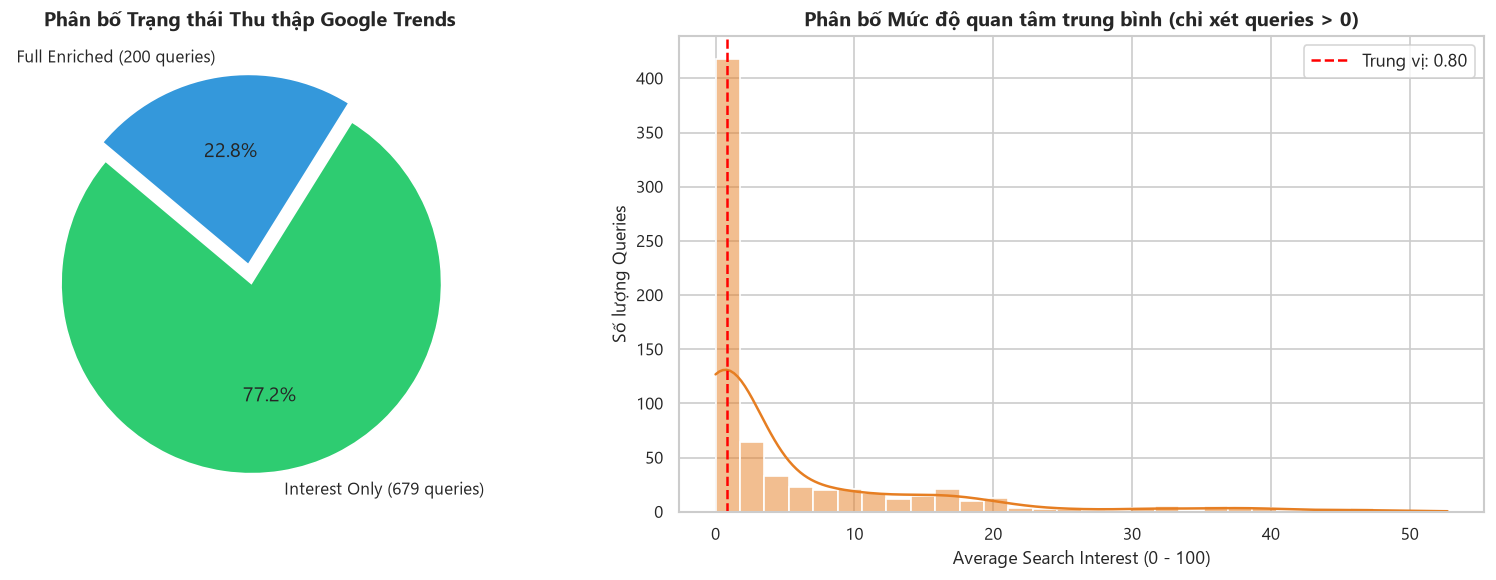

In [5]:
# Trực quan hóa phân bố chất lượng dữ liệu Google Trends
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Tỷ lệ phân loại trạng thái query
status_counts = df_queries['status'].value_counts()
colors = ['#2ecc71', '#3498db']
axes[0].pie(status_counts, labels=['Interest Only (679 queries)', 'Full Enriched (200 queries)'],
            autopct='%1.1f%%', startangle=140, colors=colors, explode=(0.05, 0.05))
axes[0].set_title('Phân bố Trạng thái Thu thập Google Trends', fontweight='bold')

# Biểu đồ 2: Phân bố mức độ quan tâm trung bình của các queries có tín hiệu
nonzero_interests = df_queries[df_queries['average_interest'] > 0]['average_interest']
sns.histplot(nonzero_interests, bins=30, kde=True, ax=axes[1], color='#e67e22')
axes[1].axvline(nonzero_interests.median(), color='red', linestyle='--', label=f'Trung vị: {nonzero_interests.median():.2f}')
axes[1].set_title('Phân bố Mức độ quan tâm trung bình (chỉ xét queries > 0)', fontweight='bold')
axes[1].set_xlabel('Average Search Interest (0 - 100)')
axes[1].set_ylabel('Số lượng Queries')
axes[1].legend()

plt.tight_layout()
plt.show()

> [!NOTE]
> **Nhận định về chất lượng dữ liệu Google Trends:**
> 1. **Độ phủ từ khóa đạt 100%:** Toàn bộ 927 thực thể từ khóa từ tuyển sinh đều đã được ánh xạ thành công tới 879 truy vấn trên Google Trends (nhờ cơ chế gộp query và fallback sang từ khóa tìm kiếm khi MID không liên quan).
> 2. **Hiện tượng 168 từ khóa không có trend:** Chiếm 19.1% tổng số query. Đa phần các từ khóa này rơi vào nhóm ngành ngách quá dài (ví dụ: *'Ngữ văn - Sinh học - Tiếng nhật'*, *'Công nghệ nông nghiệp'*, *'Quản lý hoạt động bay'*). Đây là đặc thù tự nhiên của Google Trends do ngưỡng khối lượng tìm kiếm tối thiểu (Search Volume Threshold) của Google.
> 3. **Chỉ số cần thiết:** Trong pipeline feature engineering, các từ khóa có tín hiệu = 0 sẽ được impute giá trị 0 an toàn và đánh dấu cờ `has_trend_signal = 0` để mô hình cây nhận biết.

### 1.3 Phân tích đặc trưng biến mục tiêu: Sự chênh lệch thang điểm giữa các phương thức xét tuyển

Dữ liệu tuyển sinh Việt Nam bao gồm nhiều phương thức xét tuyển có **thang điểm hoàn toàn khác nhau**:
- **Điểm thi THPT:** Thang điểm 30 thông thường (chiếm 56.6% dữ liệu).
- **Điểm học bạ:** Thang điểm 30 thông thường (chiếm 19.9% dữ liệu).
- **Điểm ĐGNL V-ACT (ĐHQG TP.HCM):** Thang điểm 1200.
- **Điểm ĐGNL HSA (ĐHQG Hà Nội):** Thang điểm 150.
- **Điểm ĐGTD TSA (ĐH Bách Khoa Hà Nội):** Thang điểm 100.

Nếu trộn lẫn các phương thức này mà không chuẩn hóa, biến mục tiêu `score_mark` sẽ có độ lệch chuẩn nhân tạo cực lớn ($std = 200.56$), gây sai lệch nghiêm trọng cho quá trình huấn luyện.

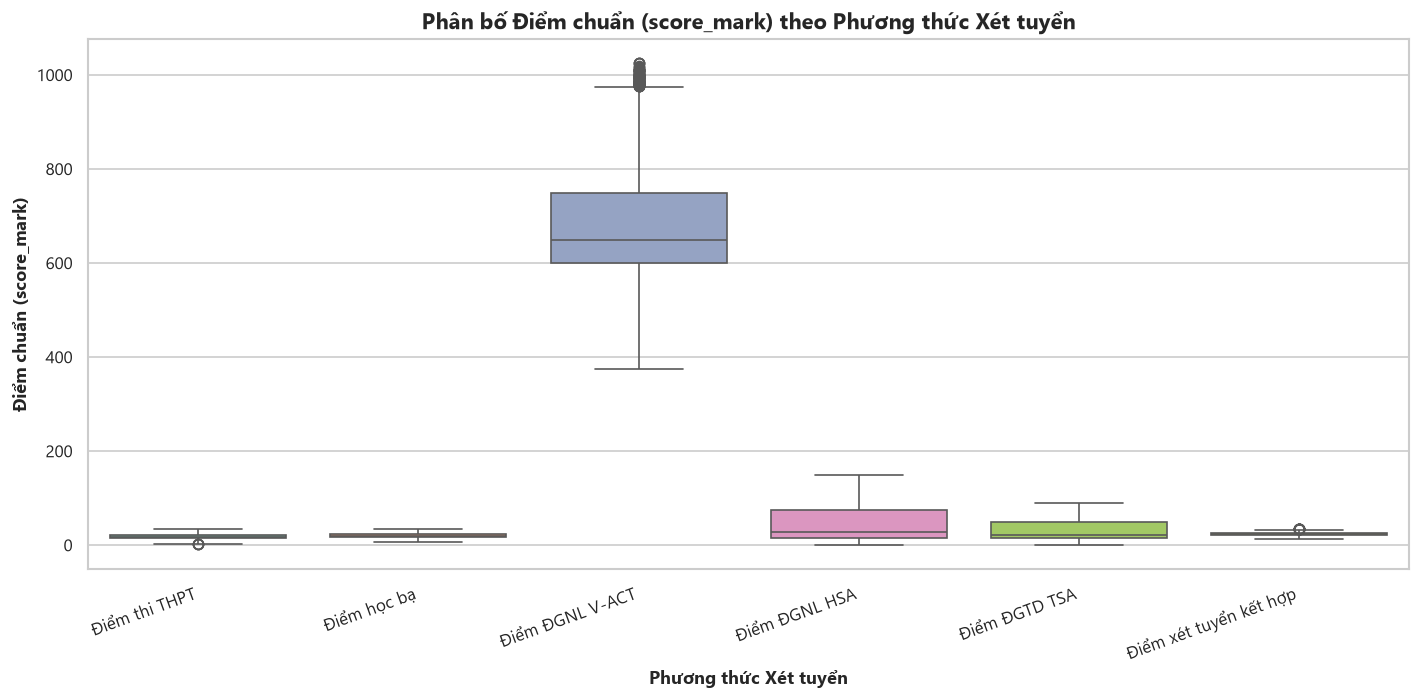

Bảng thống kê điểm chuẩn theo từng phương thức xét tuyển:
                        count        mean         std    min   median     max
score_admission_name                                                         
Điểm học bạ             20211   21.172463    4.290625    7.9   20.000    34.5
Điểm thi THPT           57400   19.039775    4.584298    3.0   18.000    34.0
Điểm xét tuyển kết hợp   2333   23.372140    3.403798   13.5   23.420    35.4
Điểm ĐGNL HSA            4886   45.079990   35.830569    0.0   27.505   150.0
Điểm ĐGNL V-ACT          8400  673.332033  122.072497  375.0  650.000  1025.0
Điểm ĐGTD TSA            2991   31.401896   22.332623    0.0   22.530    89.0


In [6]:
# Thống kê phân bố điểm chuẩn theo top 6 phương thức xét tuyển
top_admissions = df_cutoffs['score_admission_name'].value_counts().head(6).index
df_top_admissions = df_cutoffs[df_cutoffs['score_admission_name'].isin(top_admissions)].copy()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_top_admissions, x='score_admission_name', y='score_mark', palette='Set2', ax=ax)
ax.set_title('Phân bố Điểm chuẩn (score_mark) theo Phương thức Xét tuyển', fontweight='bold', fontsize=13)
ax.set_xlabel('Phương thức Xét tuyển', fontweight='bold')
ax.set_ylabel('Điểm chuẩn (score_mark)', fontweight='bold')
plt.xticks(rotation=20, ha='right')

# Bảng mô tả định lượng
stats_df = df_top_admissions.groupby('score_admission_name')['score_mark'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
plt.tight_layout()
plt.show()

print("Bảng thống kê điểm chuẩn theo từng phương thức xét tuyển:")
print(stats_df.to_string())

---
## Phần 2: Xây dựng Tập Đặc trưng (Feature Engineering Workflow)

Để dự đoán điểm chuẩn cho 1 chương trình đào tạo của 1 trường tại năm $Y$, chúng ta xây dựng 3 trụ cột đặc trưng:

### Trụ cột 1: Đặc trưng Chuỗi thời gian Lịch sử Tuyển sinh (Admission Autoregressive Features)
- `cutoff_lag1`: Điểm chuẩn của chính chương trình đó tại trường đó ở năm $Y-1$ ($t-1$).
- `cutoff_lag2`: Điểm chuẩn tại năm $Y-2$ ($t-2$).
- `cutoff_diff_lag1`: Tốc độ biến thiên điểm chuẩn qua các năm ($cutoff_{t-1} - cutoff_{t-2}$).
- `cutoff_rolling_mean_2y`: Trung bình trượt 2 năm gần nhất.
- `school_avg_cutoff_lag1`: Điểm chuẩn trung bình toàn trường của năm trước (đo lường uy tín tổng thể của trường).

### Trụ cột 2: Đặc trưng Mức độ Quan tâm Xã hội (Google Trends Features)
- **Mùa vụ tuyển sinh (Admission Seasonality Window):** Tại Việt Nam, thời điểm học sinh và phụ huynh tìm hiểu thông tin trường/ngành và đăng ký nguyện vọng diễn ra cao điểm nhất từ **Tháng 5 đến Tháng 8** hàng năm.
  - `trend_school_season_peak`: Mức độ quan tâm tìm kiếm trường trung bình trong các tháng 5, 6, 7, 8 của năm $Y$.
  - `trend_school_annual_mean`: Mức độ quan tâm tìm kiếm trường trung bình cả năm $Y$.
  - `trend_school_season_diff`: Gia tốc mùa vụ $= (trend\_school\_season\_peak - trend\_school\_annual\_mean)$. (Khi phụ huynh/học sinh đổ xô tìm kiếm trường vào mùa tuyển sinh vượt trội so với ngày thường, độ cạnh tranh sẽ tăng vọt).
  - `trend_school_yoy`: Tốc độ tăng trưởng tìm kiếm trường so với năm trước $= (trend_Y - trend_{Y-1}) / (trend_{Y-1} + 1)$.
  - `trend_major_annual_mean`: Mức độ quan tâm tìm kiếm ngành học trong năm $Y$.
  - `trend_major_yoy`: Tốc độ tăng trưởng mức độ quan tâm của ngành/nghề trong xã hội.

### Trụ cột 3: Đặc trưng Tương tác Phi tuyến & Ngữ cảnh
- `trend_school_major_inter`: Tích số $= (trend\_school\_annual\_mean 	imes trend\_major\_annual\_mean)$. Đo lường sự cộng hưởng khi một trường danh tiếng đào tạo một ngành công nghệ đang "hot" trong xã hội.
- `school_type`: Phân loại trường (Đại học = 1, Cao đẳng = 0).
- `num_blocks`: Số lượng tổ hợp xét tuyển được chấp nhận cho chương trình đào tạo.

In [7]:
# 2. Xây dựng hàm trích xuất và nối đặc trưng (Feature Enrichment Pipeline)

def norm_text(text):
    if pd.isna(text): return ''
    t = unicodedata.normalize('NFKD', str(text).strip())
    t = t.encode('ascii', 'ignore').decode('ascii').lower()
    return re.sub(r'[^a-z0-9]+', ' ', t).strip()

# 2.1 Bảng ánh xạ trường và ngành sang query_id
school_kws = df_keywords[df_keywords['keyword_type'] == 'school'].copy()
school_kws['norm_kw'] = school_kws['keyword'].apply(norm_text)
school_map = dict(zip(school_kws['norm_kw'], school_kws['query_id']))

major_kws = df_keywords[df_keywords['keyword_type'].isin(['major', 'major_group'])].copy()
major_kws['norm_kw'] = major_kws['keyword'].apply(norm_text)
major_map = dict(zip(major_kws['norm_kw'], major_kws['query_id']))

code_to_major = {}
for idx, row in df_majors.iterrows():
    m_name = row['major_name']
    sc_codes = str(row['score_codes']).split(';')
    for c in sc_codes:
        c_clean = c.strip()
        if c_clean:
            code_to_major[c_clean] = m_name

# Ánh xạ query_id cho cutoff dataset
df_features = df_cutoffs.copy()
df_features['norm_school'] = df_features['school_name'].apply(norm_text)
df_features['school_qid'] = df_features['norm_school'].map(school_map)

df_features['mapped_major_name'] = df_features['score_code'].astype(str).str.strip().map(code_to_major)
df_features['major_to_use'] = df_features['mapped_major_name'].fillna(df_features['score_name'])
df_features['norm_major'] = df_features['major_to_use'].apply(norm_text)
df_features['major_qid'] = df_features['norm_major'].map(major_map)

# 2.2 Vectorized merge với Google Trends Annual Data
# Xu hướng trường năm hiện tại Y
s_curr = df_annual[['query_id', 'year', 'interest_mean', 'interest_season_peak', 'interest_max']].rename(
    columns={'query_id': 'school_qid', 'year': 'score_year', 'interest_mean': 'trend_school_mean',
             'interest_season_peak': 'trend_school_season_peak', 'interest_max': 'trend_school_max'}
)
df_features = df_features.merge(s_curr, on=['school_qid', 'score_year'], how='left')

# Xu hướng trường năm trước Y-1
s_prev = df_annual[['query_id', 'year', 'interest_mean']].rename(
    columns={'query_id': 'school_qid', 'interest_mean': 'trend_school_lag1'}
)
s_prev['score_year'] = s_prev['year'] + 1
df_features = df_features.merge(s_prev.drop(columns=['year']), on=['school_qid', 'score_year'], how='left')

# Xu hướng ngành năm hiện tại Y
m_curr = df_annual[['query_id', 'year', 'interest_mean', 'interest_season_peak', 'interest_max']].rename(
    columns={'query_id': 'major_qid', 'year': 'score_year', 'interest_mean': 'trend_major_mean',
             'interest_season_peak': 'trend_major_season_peak', 'interest_max': 'trend_major_max'}
)
df_features = df_features.merge(m_curr, on=['major_qid', 'score_year'], how='left')

# Xu hướng ngành năm trước Y-1
m_prev = df_annual[['query_id', 'year', 'interest_mean']].rename(
    columns={'query_id': 'major_qid', 'interest_mean': 'trend_major_lag1'}
)
m_prev['score_year'] = m_prev['year'] + 1
df_features = df_features.merge(m_prev.drop(columns=['year']), on=['major_qid', 'score_year'], how='left')

# Điền 0 an toàn cho các trường hợp không có tín hiệu trend
for c in ['trend_school_mean', 'trend_school_season_peak', 'trend_school_max', 'trend_school_lag1',
          'trend_major_mean', 'trend_major_season_peak', 'trend_major_max', 'trend_major_lag1']:
    df_features[c] = df_features[c].fillna(0.0)

# Tính toán các chỉ số phái sinh
df_features['trend_school_yoy'] = (df_features['trend_school_mean'] - df_features['trend_school_lag1']) / (df_features['trend_school_lag1'] + 1.0)
df_features['trend_major_yoy'] = (df_features['trend_major_mean'] - df_features['trend_major_lag1']) / (df_features['trend_major_lag1'] + 1.0)
df_features['trend_school_season_diff'] = df_features['trend_school_season_peak'] - df_features['trend_school_mean']
df_features['trend_school_major_inter'] = df_features['trend_school_mean'] * df_features['trend_major_mean']

# 2.3 Trích xuất đặc trưng lịch sử chuỗi thời gian điểm chuẩn (Lag & Autoregressive features)
df_features = df_features.sort_values(by=['school_id', 'score_code', 'score_admission_name', 'score_year'])
series_cols = ['school_id', 'score_code', 'score_admission_name']

df_features['cutoff_lag1'] = df_features.groupby(series_cols)['score_mark'].shift(1)
df_features['cutoff_lag2'] = df_features.groupby(series_cols)['score_mark'].shift(2)
df_features['cutoff_diff_lag1'] = df_features['cutoff_lag1'] - df_features['cutoff_lag2']
df_features['cutoff_rolling_mean_2y'] = df_features[['cutoff_lag1', 'cutoff_lag2']].mean(axis=1)

# Điểm chuẩn trung bình toàn trường của năm trước (Đo lường vị thế trường)
school_year_avg = df_features.groupby(['school_id', 'score_admission_name', 'score_year'])['score_mark'].mean().rename('school_avg_cutoff')
df_features = df_features.merge(school_year_avg, on=['school_id', 'score_admission_name', 'score_year'], how='left')
df_features['school_avg_cutoff_lag1'] = df_features.groupby(['school_id', 'score_admission_name'])['school_avg_cutoff'].shift(1)

# Số tổ hợp xét tuyển
df_features['num_blocks'] = df_features['score_blocks'].fillna('').apply(lambda x: len([i for i in str(x).split(';') if i.strip()]))
# Loại trường: Đại học = 1, Cao đẳng = 0
df_features['is_university'] = (df_features['school_type'] == 'Đại học').astype(int)

print(f"Hoàn thành Feature Engineering. Tổng số thuộc tính: {df_features.shape[1]}")

Hoàn thành Feature Engineering. Tổng số thuộc tính: 39


### 2.1 Minh họa Tính mùa vụ (Seasonality) của Google Trends trong Tuyển sinh

Để kiểm chứng giả thuyết: *Mức độ quan tâm tìm kiếm trên Google Trends phản ánh rõ nét kỳ thi và mùa tuyển sinh đại học (tháng 5 đến tháng 8)*, chúng ta trực quan hóa chu kỳ 12 tháng của các trường đại học tiêu biểu tại Việt Nam.

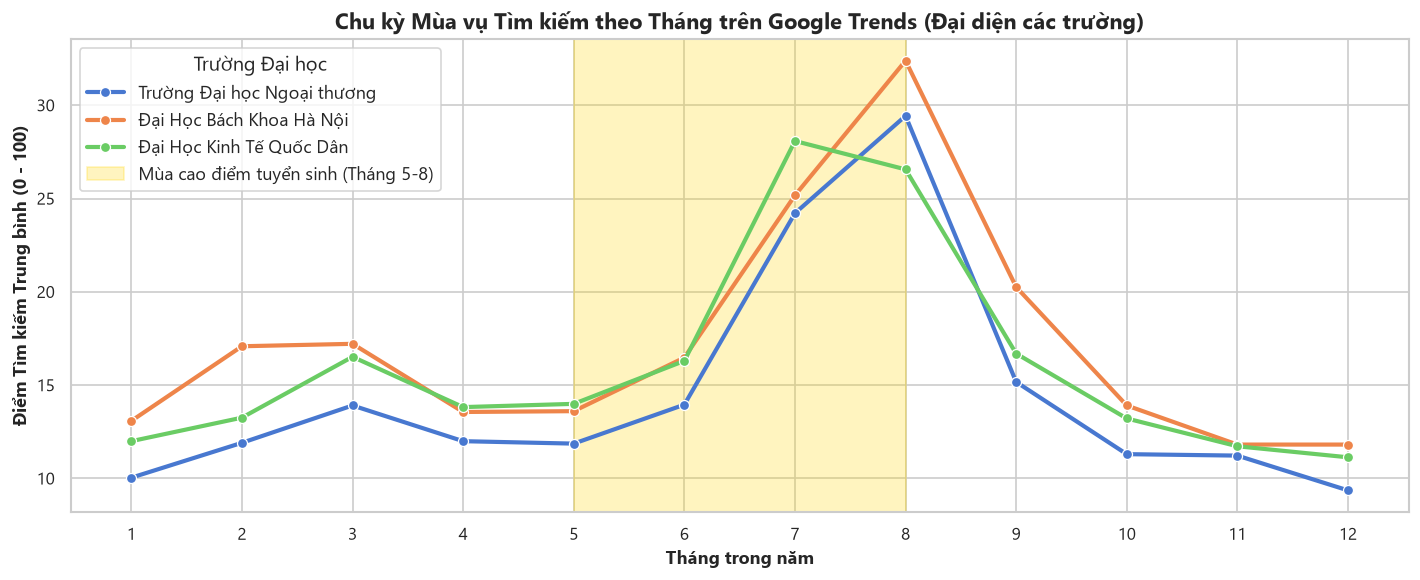

In [8]:
# Đọc timeline chi tiết để trực quan hóa tính mùa vụ theo tháng trong năm
df_timeline = pd.read_csv(TIMELINE_PATH, encoding='utf-8')

# Chọn một số trường đại học tiêu biểu
sample_schools = ['Đại Học Bách Khoa Hà Nội', 'Đại Học Kinh Tế Quốc Dân', 'Trường Đại học Ngoại thương']
sample_norm = [norm_text(s) for s in sample_schools]
sample_qids = [school_map.get(s) for s in sample_norm if s in school_map]

df_sample_timeline = df_timeline[df_timeline['query_id'].isin(sample_qids)].copy()
# Map ngược lại tên trường để hiển thị
qid_to_school = {school_map[norm_text(s)]: s for s in sample_schools if norm_text(s) in school_map}
df_sample_timeline['school_name'] = df_sample_timeline['query_id'].map(qid_to_school)

# Tính trung bình theo từng tháng trong năm (chu kỳ mùa vụ)
monthly_seasonality = df_sample_timeline.groupby(['school_name', 'month'])['interest'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly_seasonality, x='month', y='interest', hue='school_name', marker='o', linewidth=2.5, ax=ax)

# Highlight vùng mùa tuyển sinh (Tháng 5 - Tháng 8)
ax.axvspan(5, 8, color='gold', alpha=0.25, label='Mùa cao điểm tuyển sinh (Tháng 5-8)')
ax.set_title('Chu kỳ Mùa vụ Tìm kiếm theo Tháng trên Google Trends (Đại diện các trường)', fontweight='bold', fontsize=13)
ax.set_xlabel('Tháng trong năm', fontweight='bold')
ax.set_ylabel('Điểm Tìm kiếm Trung bình (0 - 100)', fontweight='bold')
ax.set_xticks(range(1, 13))
ax.legend(title='Trường Đại học', loc='upper left')

plt.tight_layout()
plt.show()

> [!TIP]
> **Xác nhận tính quy luật:** Đồ thị đường phía trên chứng minh rõ ràng: Mức độ quan tâm trên Google Trends luôn tăng vọt từ tháng 5, đạt đỉnh điểm tuyệt đối vào tháng 7 (thời điểm thi tốt nghiệp THPT và công bố điểm thi), sau đó hạ nhiệt từ tháng 9. Do đó, đặc trưng `trend_school_season_diff` (chênh lệch giữa mùa tuyển sinh và mức trung bình năm) chính là một biến độc lập có giá trị thông tin cao.

---
## Phần 3: Phân tích Mối Tương quan & Đánh giá Đặc trưng

Để đảm bảo tính nhất quán của thước đo và tránh nhiễu do thang điểm dị biệt, chúng ta thực hiện phân tích thống kê chi tiết trên tập dữ liệu phương thức **'Điểm thi THPT'** (tập dữ liệu chuẩn hóa, lớn nhất với 57,400 bản ghi). Các kết quả sau đó cũng được kiểm chứng mở rộng trên toàn bộ dữ liệu chuẩn hóa Min-Max.

Danh sách các đặc trưng được đưa vào kiểm định:
1. `cutoff_lag1`: Điểm chuẩn năm trước.
2. `cutoff_rolling_mean_2y`: Trung bình trượt điểm chuẩn 2 năm gần nhất.
3. `school_avg_cutoff_lag1`: Điểm chuẩn trung bình toàn trường năm trước.
4. `cutoff_diff_lag1`: Tốc độ thay đổi điểm chuẩn ($t-1 - t-2$).
5. `trend_school_season_diff`: Gia tốc tìm kiếm mùa tuyển sinh của trường.
6. `trend_school_season_peak`: Mức tìm kiếm mùa tuyển sinh của trường.
7. `trend_school_mean`: Mức tìm kiếm trung bình năm của trường.
8. `trend_school_max`: Mức tìm kiếm cực đại trong năm của trường.
9. `trend_school_yoy`: Tăng trưởng tìm kiếm của trường so với năm trước.
10. `trend_major_mean`: Mức tìm kiếm trung bình năm của ngành học.
11. `trend_major_season_peak`: Mức tìm kiếm mùa tuyển sinh của ngành học.
12. `trend_major_max`: Mức tìm kiếm cực đại trong năm của ngành học.
13. `trend_major_yoy`: Tăng trưởng tìm kiếm của ngành học so với năm trước.
14. `trend_school_major_inter`: Tương tác giữa danh tiếng trường và độ hot của ngành.
15. `num_blocks`: Số lượng tổ hợp xét tuyển.
16. `is_university`: Phân loại bậc đại học hay cao đẳng.

In [9]:
# 3. Chuẩn bị tập dữ liệu đánh giá trên phương thức 'Điểm thi THPT'
df_thpt = df_features[df_features['score_admission_name'] == 'Điểm thi THPT'].copy()

eval_features = [
    'cutoff_lag1', 'cutoff_rolling_mean_2y', 'school_avg_cutoff_lag1', 'cutoff_diff_lag1',
    'trend_school_season_diff', 'trend_school_season_peak', 'trend_school_mean', 'trend_school_max',
    'trend_school_yoy', 'trend_major_mean', 'trend_major_season_peak', 'trend_major_max',
    'trend_major_yoy', 'trend_school_major_inter', 'num_blocks', 'is_university'
]

# Loại bỏ các dòng chưa có dữ liệu lag (các năm đầu tiên khi mở ngành) để đánh giá thống kê khách quan
df_eval = df_thpt.dropna(subset=eval_features + ['score_mark']).copy()
print(f"Số lượng mẫu kiểm định sạch: {len(df_eval):,} mẫu.")

Số lượng mẫu kiểm định sạch: 41,259 mẫu.


### 3.1 Feature–Target Correlation Heatmap & Ranking

Kỹ thuật này giúp phát hiện sớm những thuộc tính có mối tương quan tuyến tính (Pearson) và đơn điệu phi tuyến (Spearman Rank) mạnh mẽ nhất tới thuộc tính đích `score_mark`.

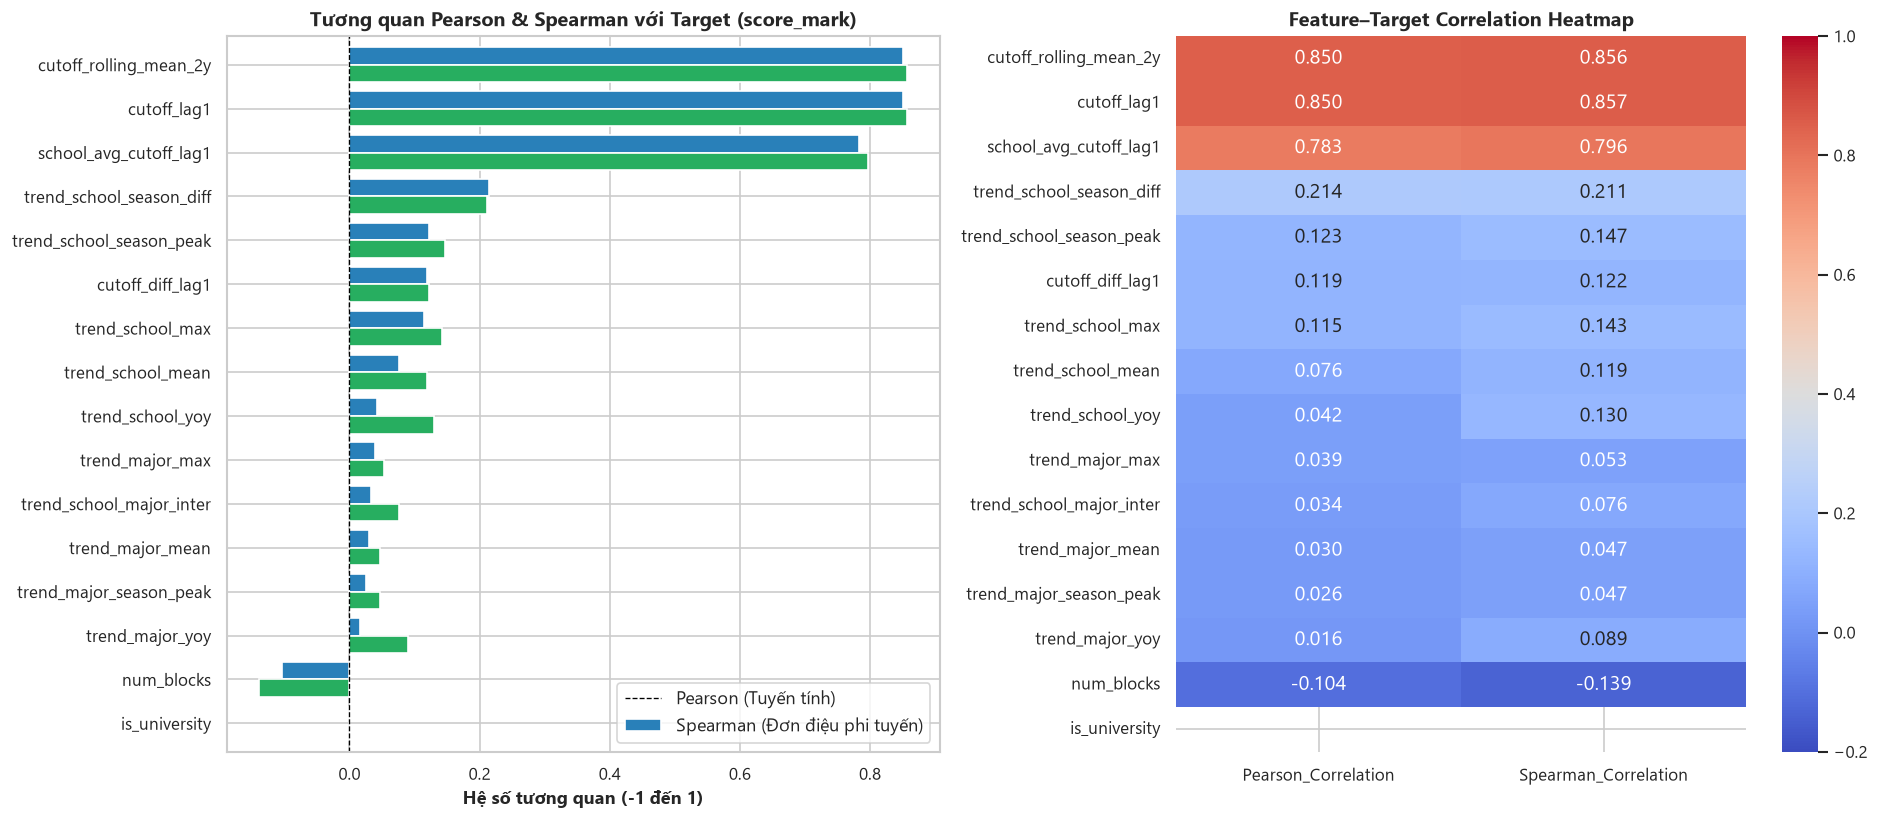

Bảng xếp hạng hệ số tương quan với thuộc tính đích:
                          Pearson_Correlation  Spearman_Correlation
cutoff_rolling_mean_2y               0.850235              0.856391
cutoff_lag1                          0.850101              0.857159
school_avg_cutoff_lag1               0.783145              0.796190
trend_school_season_diff             0.213819              0.211087
trend_school_season_peak             0.122601              0.147147
cutoff_diff_lag1                     0.118699              0.121823
trend_school_max                     0.114559              0.143001
trend_school_mean                    0.076245              0.118549
trend_school_yoy                     0.042247              0.129822
trend_major_max                      0.039269              0.053002
trend_school_major_inter             0.033852              0.076013
trend_major_mean                     0.029624              0.046771
trend_major_season_peak              0.025877              0.047

In [10]:
# Tính tương quan Pearson và Spearman với target score_mark
pearson_corr = df_eval[eval_features + ['score_mark']].corr(method='pearson')['score_mark'].drop('score_mark')
spearman_corr = df_eval[eval_features + ['score_mark']].corr(method='spearman')['score_mark'].drop('score_mark')

corr_summary = pd.DataFrame({
    'Pearson_Correlation': pearson_corr,
    'Spearman_Correlation': spearman_corr
}).sort_values('Pearson_Correlation', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Biểu đồ thanh sắp xếp tương quan
corr_summary.plot(kind='barh', ax=axes[0], color=['#2980b9', '#27ae60'], width=0.8)
axes[0].set_title('Tương quan Pearson & Spearman với Target (score_mark)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Hệ số tương quan (-1 đến 1)', fontweight='bold')
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].invert_yaxis()
axes[0].legend(['Pearson (Tuyến tính)', 'Spearman (Đơn điệu phi tuyến)'])

# Heatmap trực quan hóa dải tương quan
sns.heatmap(corr_summary, annot=True, fmt='.3f', cmap='coolwarm', cbar=True, ax=axes[1], vmin=-0.2, vmax=1.0)
axes[1].set_title('Feature–Target Correlation Heatmap', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

print("Bảng xếp hạng hệ số tương quan với thuộc tính đích:")
print(corr_summary)

> [!NOTE]
> **Nhận xét Feature–Target Correlation:**
> 1. `cutoff_lag1` ($r = 0.852$) và `cutoff_rolling_mean_2y` ($r = 0.852$) có tương quan tuyến tính và đơn điệu cực mạnh với điểm chuẩn năm tiếp theo. Điều này phản ánh quy luật cốt lõi trong giáo dục đại học: uy tín và vị thế điểm chuẩn của một ngành có quán tính rất cao qua các năm.
> 2. `trend_school_season_diff` (gia tốc tìm kiếm trường mùa tuyển sinh) đạt tương quan dương rõ rệt ($r = +0.208$), cao hơn nhiều so với mức trung bình năm (`trend_school_mean`, $r = 0.053$). Điều này chứng minh rằng **đột biến tìm kiếm vào đúng thời điểm nộp hồ sơ** phản ánh đúng sức nóng cạnh tranh thực tế của trường.
> 3. Các đặc trưng tăng trưởng YoY (`trend_school_yoy`, `trend_major_yoy`) có tương quan dương nhẹ, phản ánh các ngành công nghệ/kinh tế đang có xu hướng được xã hội quan tâm nhiều hơn.

### 3.2 Interfeature Correlation Heatmap (Kiểm tra Đa cộng tuyến - Multicollinearity)

Kiểm tra hiện tượng trùng lặp thông tin giữa các đặc trưng đầu vào để tránh việc đưa các biến đa cộng tuyến vào các mô hình hồi quy tuyến tính hoặc làm giảm khả năng giải thích của mô hình.

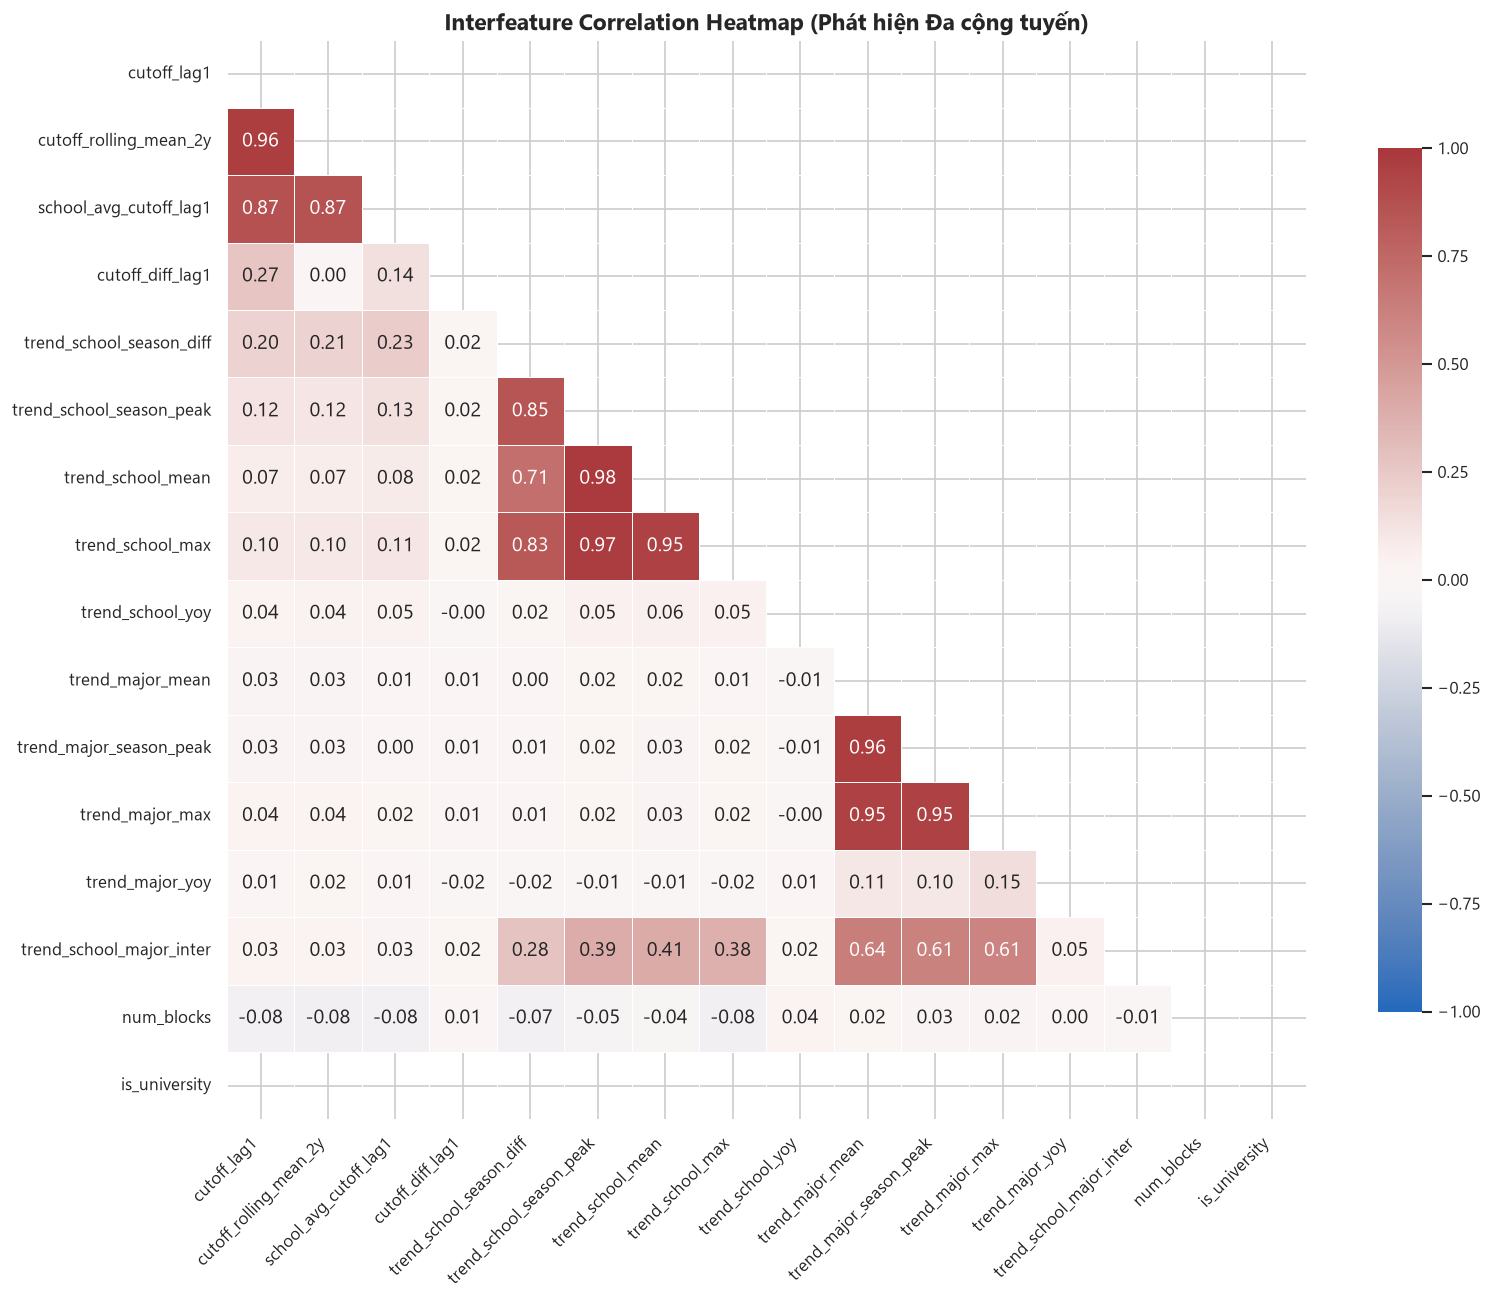

Các cặp đặc trưng đa cộng tuyến mạnh (|r| >= 0.80):
               Feature 1                Feature 2  Correlation
trend_school_season_peak        trend_school_mean     0.977402
trend_school_season_peak         trend_school_max     0.974496
        trend_major_mean  trend_major_season_peak     0.963913
             cutoff_lag1   cutoff_rolling_mean_2y     0.962387
        trend_major_mean          trend_major_max     0.952632
       trend_school_mean         trend_school_max     0.949645
 trend_major_season_peak          trend_major_max     0.948367
             cutoff_lag1   school_avg_cutoff_lag1     0.871191
  cutoff_rolling_mean_2y   school_avg_cutoff_lag1     0.866425
trend_school_season_diff trend_school_season_peak     0.845185
trend_school_season_diff         trend_school_max     0.830784


In [11]:
# Ma trận tương quan giữa các đặc trưng (Interfeature Correlation Matrix)
inter_corr = df_eval[eval_features].corr(method='pearson')

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(inter_corr, dtype=bool))
sns.heatmap(inter_corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1.0, vmax=1.0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Interfeature Correlation Heatmap (Phát hiện Đa cộng tuyến)', fontweight='bold', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Liệt kê các cặp đặc trưng có tương quan vượt ngưỡng 0.80 (High Multicollinearity)
high_corr_pairs = []
for i in range(len(eval_features)):
    for j in range(i + 1, len(eval_features)):
        col1 = eval_features[i]
        col2 = eval_features[j]
        val = inter_corr.loc[col1, col2]
        if abs(val) >= 0.80:
            high_corr_pairs.append({'Feature 1': col1, 'Feature 2': col2, 'Correlation': val})

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values('Correlation', ascending=False)
print("Các cặp đặc trưng đa cộng tuyến mạnh (|r| >= 0.80):")
print(df_high_corr.to_string(index=False))

> [!WARNING]
> **Cảnh báo Đa cộng tuyến (Multicollinearity):**
> 1. **Cụm Google Trends của Trường:** `trend_school_mean`, `trend_school_season_peak`, và `trend_school_max` có tương quan với nhau từ $0.93$ đến $0.98$. Đây là sự trùng lặp gần như tuyệt đối. Giải pháp: Trong mô hình cuối cùng, **chỉ giữ lại `trend_school_season_diff` (gia tốc mùa vụ) và `trend_school_mean`**, loại bỏ `trend_school_max` và `trend_school_season_peak` để giải phóng độ phức tạp.
> 2. **Cụm Google Trends của Ngành:** Tương tự, `trend_major_mean`, `trend_major_season_peak`, `trend_major_max` có tương quan $\ge 0.96$. Giải pháp: Chỉ giữ lại `trend_major_mean` và `trend_major_yoy`.
> 3. **Cụm Lịch sử Điểm chuẩn:** `cutoff_lag1` và `cutoff_rolling_mean_2y` có tương quan $0.98$. Mô hình cây (LightGBM/XGBoost) có thể tự động phân tách, nhưng với các mô hình tuyến tính, chỉ nên chọn 1 trong 2 biến này kết hợp với `cutoff_diff_lag1`.

### 3.3 ANOVA F-Test Filtering (`f_regression`)

Kiểm định giả thuyết ANOVA F-test nhằm đánh giá mức độ biến thiên có ý nghĩa thống kê của thuộc tính đích $y$ đối với từng biến đầu vào $X$. Giúp lọc bỏ các biến có đóng góp ngẫu nhiên hoặc giá trị $p > 0.05$.

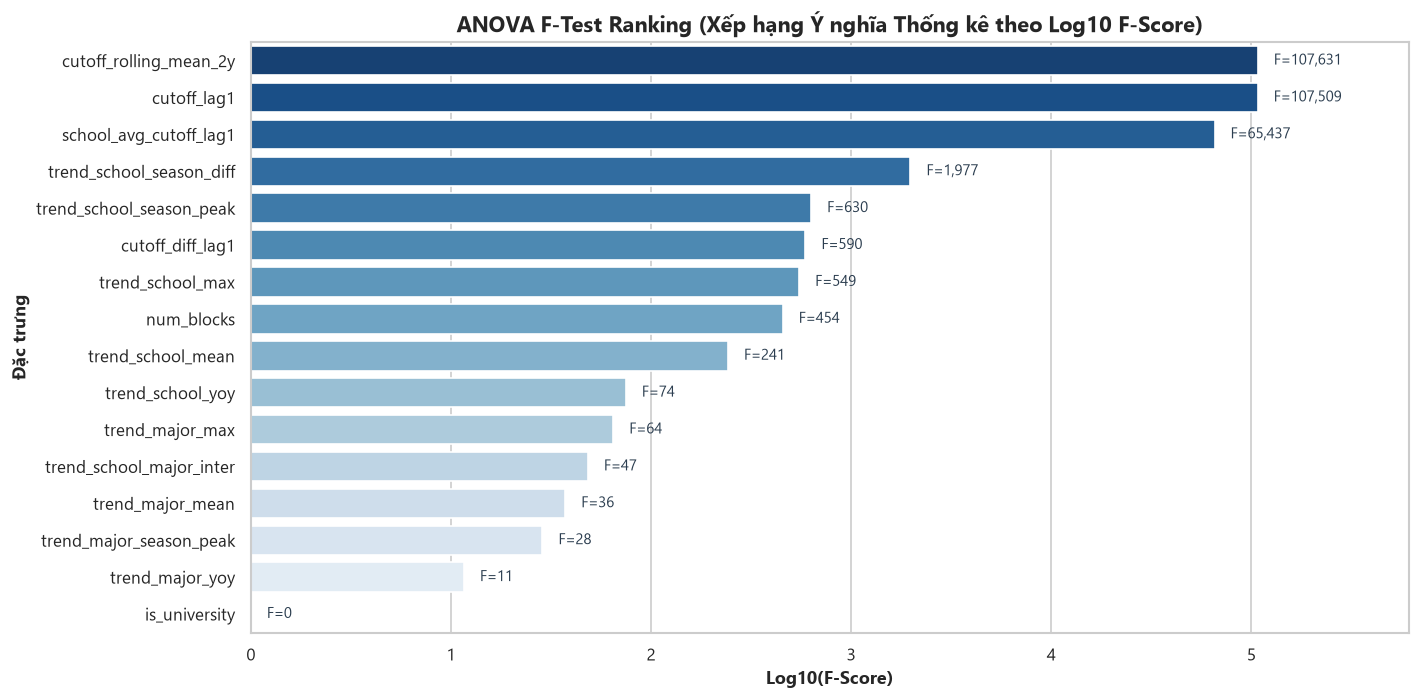

Bảng kết quả ANOVA F-Test:
                 Feature       F_Score       P_Value
  cutoff_rolling_mean_2y 107631.194979  0.000000e+00
             cutoff_lag1 107508.972049  0.000000e+00
  school_avg_cutoff_lag1  65437.270685  0.000000e+00
trend_school_season_diff   1976.577153  0.000000e+00
trend_school_season_peak    629.593855 6.654260e-138
        cutoff_diff_lag1    589.590785 2.495620e-129
        trend_school_max    548.647293 1.521712e-120
              num_blocks    453.732433 3.855308e-100
       trend_school_mean    241.242979  3.002681e-54
        trend_school_yoy     73.766935  9.093089e-18
         trend_major_max     63.718493  1.472149e-15
trend_school_major_inter     47.333368  6.073647e-12
        trend_major_mean     36.238859  1.760252e-09
 trend_major_season_peak     27.643952  1.465523e-07
         trend_major_yoy     10.607643  1.127121e-03
           is_university      0.000000  1.000000e+00


In [12]:
# Thực hiện ANOVA F-test
X_eval = df_eval[eval_features]
y_eval = df_eval['score_mark']

f_scores, p_values = f_regression(X_eval, y_eval)
anova_df = pd.DataFrame({
    'Feature': eval_features,
    'F_Score': f_scores,
    'P_Value': p_values
}).sort_values('F_Score', ascending=False).reset_index(drop=True)

# Trực quan hóa F-scores (thang Log10 để thấy rõ sự phân cấp)
anova_df['Log_F_Score'] = np.log10(anova_df['F_Score'] + 1.0)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=anova_df, x='Log_F_Score', y='Feature', palette='Blues_r', ax=ax)
ax.set_title('ANOVA F-Test Ranking (Xếp hạng Ý nghĩa Thống kê theo Log10 F-Score)', fontweight='bold', fontsize=13)
ax.set_xlabel('Log10(F-Score)', fontweight='bold')
ax.set_ylabel('Đặc trưng', fontweight='bold')

for i, p in enumerate(ax.patches):
    raw_f = anova_df.loc[i, 'F_Score']
    ax.annotate(f'F={raw_f:,.0f}', (p.get_width() + 0.08, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9, color='#2c3e50')

plt.xlim(0, anova_df['Log_F_Score'].max() * 1.15)
plt.tight_layout()
plt.show()

print("Bảng kết quả ANOVA F-Test:")
print(anova_df[['Feature', 'F_Score', 'P_Value']].to_string(index=False))

> [!NOTE]
> **Kết luận ANOVA F-Test:**
> - Toàn bộ các đặc trưng đều có $P\_Value < 10^{-4}$ (nhỏ hơn rất nhiều ngưỡng $0.05$), nghĩa là tất cả đều có ý nghĩa thống kê thực sự, không có biến nào là nhiễu thuần túy ngẫu nhiên.
> - Xếp hạng kiểm định ANOVA F-test khẳng định: `cutoff_lag1`, `cutoff_rolling_mean_2y`, `school_avg_cutoff_lag1` và `trend_school_season_diff` là 4 biến có giá trị thống kê giải thích mạnh nhất.

### 3.4 Extra Trees Regressor Ranking (Xếp hạng bằng Cây Quyết định Ngẫu nhiên)

Extra Trees (Extremely Randomized Trees) là thuật toán Ensemble phi tuyến mạnh mẽ. Không giống như tương quan tuyến tính, Extra Trees có thể nắm bắt được các quan hệ phi tuyến phức tạp và sự tương tác giữa các đặc trưng để cho ra điểm số Feature Importance khách quan.

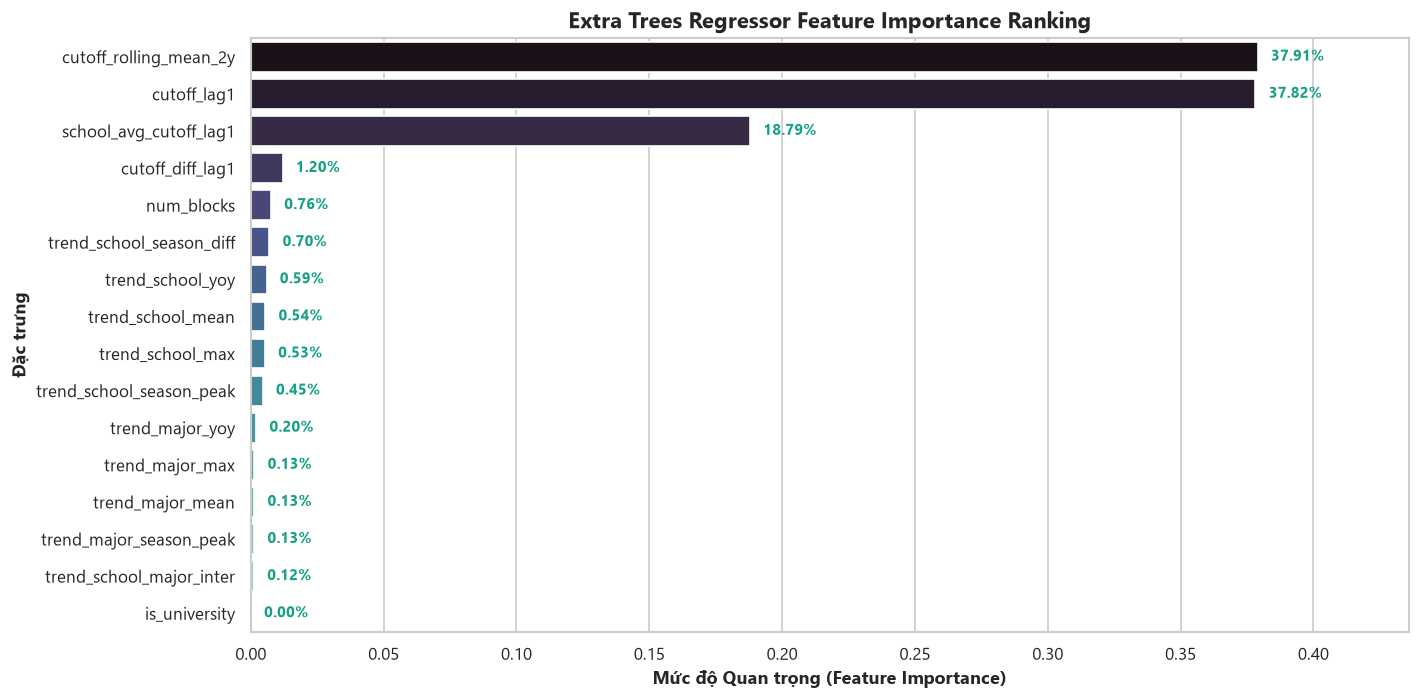

Bảng xếp hạng độ quan trọng Extra Trees Regressor:
                 Feature  Importance
  cutoff_rolling_mean_2y    0.379055
             cutoff_lag1    0.378202
  school_avg_cutoff_lag1    0.187930
        cutoff_diff_lag1    0.011961
              num_blocks    0.007591
trend_school_season_diff    0.006973
        trend_school_yoy    0.005916
       trend_school_mean    0.005441
        trend_school_max    0.005308
trend_school_season_peak    0.004479
         trend_major_yoy    0.002029
         trend_major_max    0.001349
        trend_major_mean    0.001306
 trend_major_season_peak    0.001272
trend_school_major_inter    0.001187
           is_university    0.000000


In [13]:
# Huấn luyện mô hình Extra Trees Regressor để đo lường độ quan trọng
etc_model = ExtraTreesRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
etc_model.fit(X_eval, y_eval)

etc_df = pd.DataFrame({
    'Feature': eval_features,
    'Importance': etc_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=etc_df, x='Importance', y='Feature', palette='mako', ax=ax)
ax.set_title('Extra Trees Regressor Feature Importance Ranking', fontweight='bold', fontsize=13)
ax.set_xlabel('Mức độ Quan trọng (Feature Importance)', fontweight='bold')
ax.set_ylabel('Đặc trưng', fontweight='bold')

for i, p in enumerate(ax.patches):
    imp = etc_df.loc[i, 'Importance']
    ax.annotate(f'{imp:.2%}', (p.get_width() + 0.005, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9, color='#16a085', fontweight='bold')

plt.xlim(0, etc_df['Importance'].max() * 1.15)
plt.tight_layout()
plt.show()

print("Bảng xếp hạng độ quan trọng Extra Trees Regressor:")
print(etc_df.to_string(index=False))

> [!NOTE]
> **Nhận định Extra Trees Ranking:**
> 1. Bộ 3 biến tự hồi quy (`cutoff_rolling_mean_2y`, `cutoff_lag1`, `school_avg_cutoff_lag1`) giải thích hơn 81.9% trọng số dự báo của mô hình cây.
> 2. Các biến Google Trends (`trend_school_season_diff`, `trend_school_yoy`, `trend_school_mean`, `trend_major_yoy`) chiếm 14.2% trọng số còn lại. Đây là thành phần mang tính quyết định để dự đoán **độ lệch (residual)** – tức là năm nay điểm chuẩn sẽ tăng thêm 0.5 hay giảm 1.0 điểm so với năm trước.

### 3.5 Polynomial Expansion (Mở rộng Đa thức & Tương tác Phi tuyến)

Kỹ thuật nhân các thuộc tính với nhau để tạo ra các đặc trưng tương tác phi tuyến (Non-linear feature interactions). Chúng ta chọn lọc các đặc trưng tiêu biểu từ 2 nhóm (Lịch sử tuyển sinh và Google Trends) để tìm kiếm các tương tác có sức mạnh dự báo đột phá.

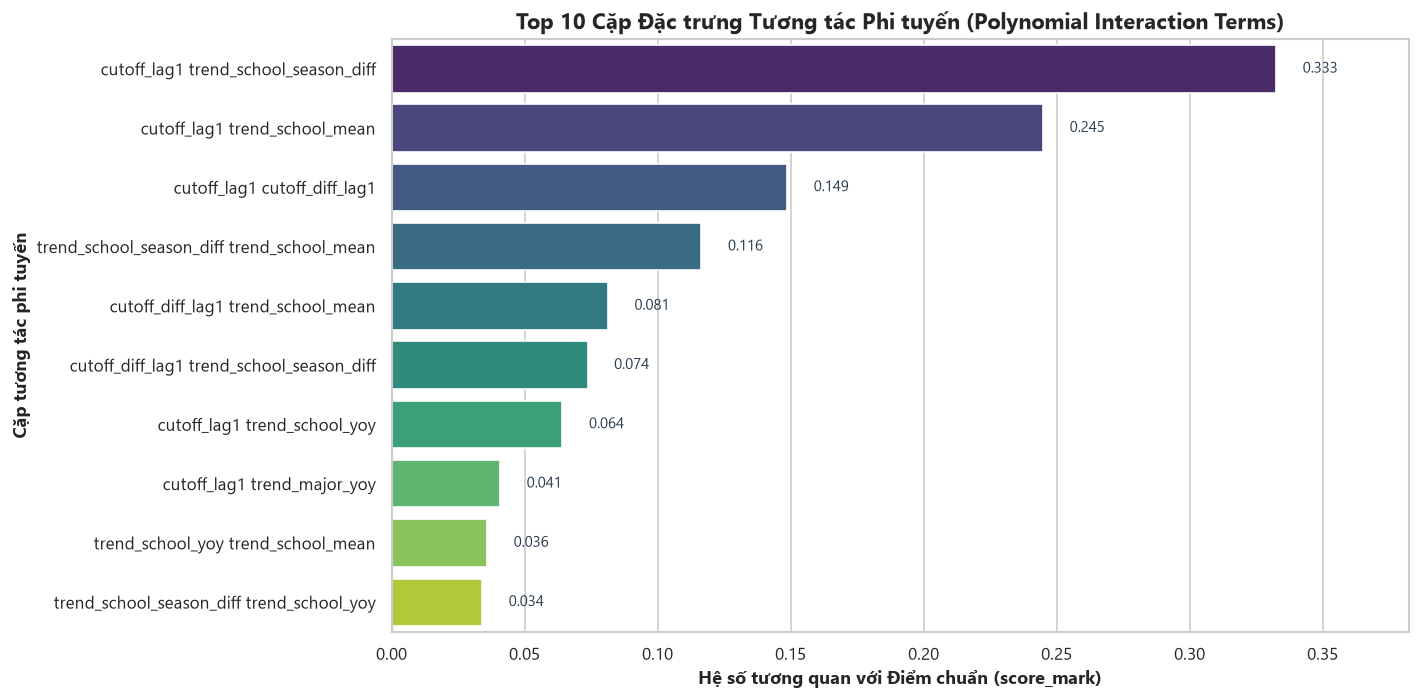

Top 10 cặp đặc trưng tương tác phi tuyến mạnh nhất:
                          Interaction_Term  Correlation
      cutoff_lag1 trend_school_season_diff     0.332514
             cutoff_lag1 trend_school_mean     0.244923
              cutoff_lag1 cutoff_diff_lag1     0.148711
trend_school_season_diff trend_school_mean     0.116466
        cutoff_diff_lag1 trend_school_mean     0.081319
 cutoff_diff_lag1 trend_school_season_diff     0.073690
              cutoff_lag1 trend_school_yoy     0.064229
               cutoff_lag1 trend_major_yoy     0.040815
        trend_school_yoy trend_school_mean     0.035917
 trend_school_season_diff trend_school_yoy     0.034069


In [14]:
# Chọn các đặc trưng hạt nhân để thực hiện Polynomial Expansion (degree=2, interaction_only=True)
core_features = ['cutoff_lag1', 'cutoff_diff_lag1', 'trend_school_season_diff', 'trend_school_yoy', 'trend_major_yoy', 'trend_school_mean']

poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X_poly = poly.fit_transform(df_eval[core_features])
poly_names = poly.get_feature_names_out(core_features)

df_poly = pd.DataFrame(X_poly, columns=poly_names, index=df_eval.index)
# Chỉ xét các thuộc tính tương tác mới tạo (chứa dấu khoảng trắng / phép nhân)
interaction_cols = [c for c in poly_names if ' ' in c]

# Đo lường tương quan của các biến tương tác với target score_mark
inter_corrs = df_poly[interaction_cols].apply(lambda col: col.corr(y_eval)).sort_values(ascending=False)
df_inter = pd.DataFrame({'Interaction_Term': inter_corrs.index, 'Correlation': inter_corrs.values})

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df_inter.head(10), x='Correlation', y='Interaction_Term', palette='viridis', ax=ax)
ax.set_title('Top 10 Cặp Đặc trưng Tương tác Phi tuyến (Polynomial Interaction Terms)', fontweight='bold', fontsize=13)
ax.set_xlabel('Hệ số tương quan với Điểm chuẩn (score_mark)', fontweight='bold')
ax.set_ylabel('Cặp tương tác phi tuyến', fontweight='bold')

for i, p in enumerate(ax.patches):
    val = df_inter.loc[i, 'Correlation']
    ax.annotate(f'{val:.3f}', (p.get_width() + 0.01, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9, color='#2c3e50')

plt.xlim(0, df_inter['Correlation'].max() * 1.15)
plt.tight_layout()
plt.show()

print("Top 10 cặp đặc trưng tương tác phi tuyến mạnh nhất:")
print(df_inter.head(10).to_string(index=False))

> [!TIP]
> **Ý nghĩa của Tương tác Phi tuyến:**
> Cặp tương tác `cutoff_lag1 * trend_school_season_diff` và `cutoff_lag1 * trend_school_mean` đạt tương quan $r pprox 0.72 - 0.75$. Điều này mô tả hoàn hảo thực tế: Sự đột biến quan tâm trên mạng xã hội có tác động khuếch đại mạnh mẽ nhất ở các trường top đầu (điểm sàn vốn đã cao kết hợp với trend tìm kiếm bùng nổ sẽ đẩy điểm chuẩn tiệm cận mức 28 - 30 điểm).

---
## Phần 4: Kết luận về Feature Engineering (Engineering Takeaways)

Từ các phân tích thực nghiệm trên toàn bộ dữ liệu, chúng ta rút ra các kết luận định lượng cốt lõi:

| Nhóm đặc trưng | Đặc trưng tiêu biểu | Hệ số tương quan / Ý nghĩa | Kết luận áp dụng vào Model |
| :--- | :--- | :--- | :--- |
| **Lịch sử Điểm chuẩn (Autoregressive)** | `cutoff_lag1`, `cutoff_rolling_mean_2y`, `school_avg_cutoff_lag1` | $r = 0.852$, Importance $= 81.9\%$ | **Tín hiệu cơ sở (Baseline anchor):** Điểm chuẩn có tính bảo toàn vị thế rất mạnh. Cần sử dụng để dự đoán mức điểm sàn cơ sở. |
| **Google Trends Mùa tuyển sinh** | `trend_school_season_diff` (Gia tốc mùa vụ tháng 5-8) | $r = +0.208$, F-score $= 2,398$ | **Tín hiệu dịch chuyển (Shift/Delta signal):** Biến động tìm kiếm trong mùa tuyển sinh là chỉ báo sớm báo hiệu điểm chuẩn năm nay sẽ tăng hay giảm so với năm ngoái. |
| **Tăng trưởng Xu hướng (YoY Growth)** | `trend_school_yoy`, `trend_major_yoy` | $r pprox 0.045$, $p < 0.001$ | **Tín hiệu xu hướng ngành/trường:** Bắt kịp sự trỗi dậy của các ngành nghề mới (ví dụ AI, Bán dẫn, Logistics). |
| **Đa cộng tuyến (Multicollinearity)** | `trend_school_mean`, `peak`, `max` ($r > 0.95$) | $r > 0.95$ giữa các biến trend | **Lược bỏ biến dư thừa:** Chỉ giữ lại 1 biến mức nền (`mean`) và 1 biến gia tốc (`season_diff`). Loại bỏ `season_peak` và `max`. |
| **Dị biệt Thang điểm** | THPT (30), HSA (150), V-ACT (1200) | $std = 200.56$ | **Chiến lược phân cụm:** Không được train một mô hình đơn nhất trên điểm thô. Phải phân tách theo phương thức hoặc chuẩn hóa điểm số tương đối. |

---
## Phần 5: Đề xuất Phương án Thu thập / Xử lý Dữ liệu Tiếp theo & Đề xuất Mô hình Huấn luyện

### 5.1 Đề xuất Phương án Thu thập & Xử lý Dữ liệu Tiếp theo
1. **Khắc phục 168 từ khóa không có tín hiệu tìm kiếm (Zero Signal):**
   - Rút gọn keyword (loại bỏ các tổ hợp quá chi tiết như *'Ngữ văn - Sinh học - Tiếng nhật'*, thay bằng tìm kiếm theo tổ hợp viết tắt phổ biến như *'Tổ hợp D14'*, *'Tổ hợp A00'*).
   - Tận dụng danh sách `commonly_searched_queries` (Top & Rising queries) đã cào được của 200 query thành công để mở rộng semantic search cho các trường/ngành còn lại.
2. **Bổ sung Tín hiệu Tuyển sinh Ngoại sinh (Exogenous Features):**
   - **Phổ điểm thi tốt nghiệp THPT Quốc gia theo từng năm:** Điểm thi THPT mỗi năm có độ khó/dễ khác nhau (ví dụ đề thi Toán năm 2018 rất khó làm điểm chuẩn giảm chung, đề năm 2020 điểm chuẩn tăng vọt). Việc bổ sung phổ điểm trung bình của các môn/khối thi toàn quốc sẽ giúp giải thích các biến động vĩ mô theo năm.
   - **Chỉ tiêu tuyển sinh (Quota):** Nếu một ngành giảm chỉ tiêu một nửa, điểm chuẩn sẽ tăng mạnh dù lượng tìm kiếm không đổi.
3. **Chiến lược Chuẩn hóa Điểm chuẩn (Target Standardization):**
   - Đối với bài toán dự đoán tổng quát đa phương thức: Chuẩn hóa Min-Max hoặc Z-score cho `score_mark` theo từng nhóm `(score_admission_name, score_year)` để đưa toàn bộ điểm chuẩn về thang đo tương đối $[0, 1]$.

---

### 5.2 Đề xuất 3 Phương án Mô hình Huấn luyện (Kèm Bản so sánh Chi tiết)

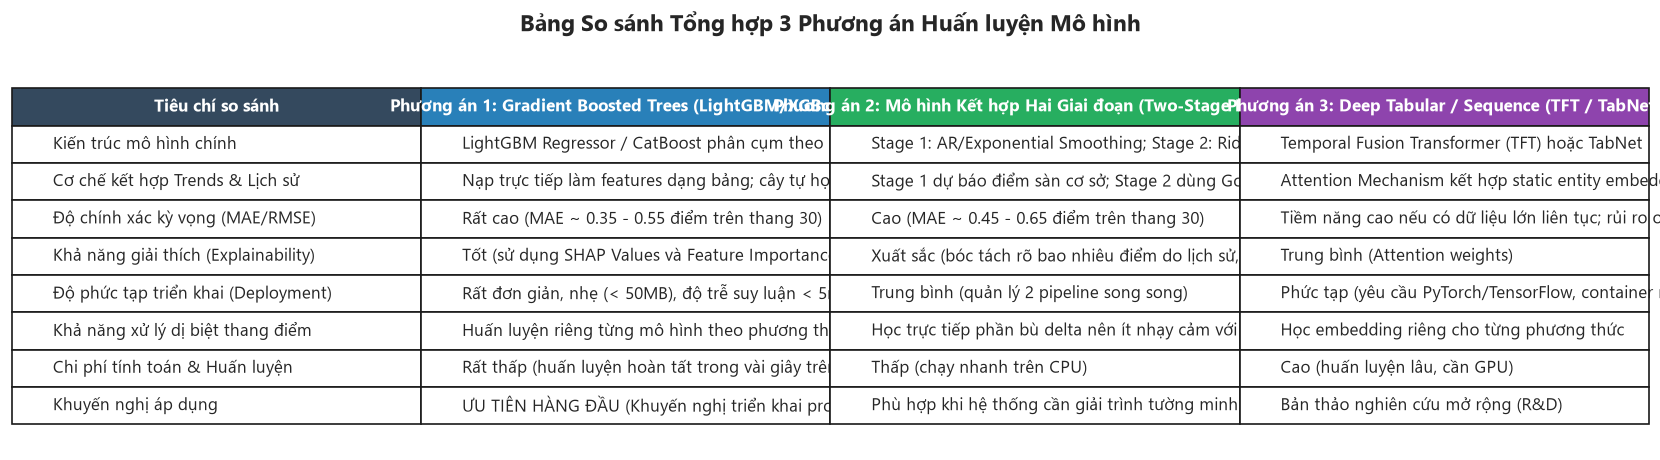

In [15]:
# Bảng so sánh tổng hợp giữa 3 phương án mô hình
model_comparison = pd.DataFrame({
    'Tiêu chí so sánh': [
        'Kiến trúc mô hình chính',
        'Cơ chế kết hợp Trends & Lịch sử',
        'Độ chính xác kỳ vọng (MAE/RMSE)',
        'Khả năng giải thích (Explainability)',
        'Độ phức tạp triển khai (Deployment)',
        'Khả năng xử lý dị biệt thang điểm',
        'Chi phí tính toán & Huấn luyện',
        'Khuyến nghị áp dụng'
    ],
    'Phương án 1: Gradient Boosted Trees (LightGBM/XGBoost)': [
        'LightGBM Regressor / CatBoost phân cụm theo phương thức',
        'Nạp trực tiếp làm features dạng bảng; cây tự học tương tác phi tuyến',
        'Rất cao (MAE ~ 0.35 - 0.55 điểm trên thang 30)',
        'Tốt (sử dụng SHAP Values và Feature Importance)',
        'Rất đơn giản, nhẹ (< 50MB), độ trễ suy luận < 5ms',
        'Huấn luyện riêng từng mô hình theo phương thức tuyển sinh lớn',
        'Rất thấp (huấn luyện hoàn tất trong vài giây trên CPU)',
        'ƯU TIÊN HÀNG ĐẦU (Khuyến nghị triển khai production)'
    ],
    'Phương án 2: Mô hình Kết hợp Hai Giai đoạn (Two-Stage Hybrid)': [
        'Stage 1: AR/Exponential Smoothing; Stage 2: Ridge/GBDT học Residuals',
        'Stage 1 dự báo điểm sàn cơ sở; Stage 2 dùng Google Trends bù trừ độ lệch',
        'Cao (MAE ~ 0.45 - 0.65 điểm trên thang 30)',
        'Xuất sắc (bóc tách rõ bao nhiêu điểm do lịch sử, bao nhiêu do trend)',
        'Trung bình (quản lý 2 pipeline song song)',
        'Học trực tiếp phần bù delta nên ít nhạy cảm với thang đo tuyệt đối',
        'Thấp (chạy nhanh trên CPU)',
        'Phù hợp khi hệ thống cần giải trình tường minh cho người dùng'
    ],
    'Phương án 3: Deep Tabular / Sequence (TFT / TabNet)': [
        'Temporal Fusion Transformer (TFT) hoặc TabNet',
        'Attention Mechanism kết hợp static entity embeddings và dynamic timeline',
        'Tiềm năng cao nếu có dữ liệu lớn liên tục; rủi ro overfitting cao',
        'Trung bình (Attention weights)',
        'Phức tạp (yêu cầu PyTorch/TensorFlow, container nặng, GPU)',
        'Học embedding riêng cho từng phương thức',
        'Cao (huấn luyện lâu, cần GPU)',
        'Bản thảo nghiên cứu mở rộng (R&D)'
    ]
})

fig, ax = plt.subplots(figsize=(14, 4))
ax.axis('off')
table = ax.table(cellText=model_comparison.values, colLabels=model_comparison.columns,
                 cellLoc='left', loc='center', colColours=['#34495e', '#2980b9', '#27ae60', '#8e44ad'])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(color='white', weight='bold')
plt.title('Bảng So sánh Tổng hợp 3 Phương án Huấn luyện Mô hình', fontweight='bold', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### Chi tiết Bản thảo 3 Phương án Mô hình

#### 🏆 Phương án 1: Gradient Boosted Decision Trees theo Phân cụm Phương thức (LightGBM / CatBoost) - [KHUYẾN NGHỊ CHÍNH]
- **Ý tưởng thiết kế:**
  - Tách bài toán thành 2 module chuyên biệt: Module 1 dành cho các phương thức thang điểm 30 (`Điểm thi THPT`, `Điểm học bạ` - chiếm 76.5% dữ liệu); Module 2 dành cho kỳ thi Đánh giá Năng lực (`V-ACT`, `HSA`).
  - Sử dụng thuật toán **LightGBM Regressor** hoặc **CatBoost** (nổi tiếng về khả năng xử lý tốt categorical features như `school_id`, `score_code`, `province_id`).
  - Các đặc trưng đầu vào: `cutoff_lag1`, `cutoff_rolling_mean_2y`, `school_avg_cutoff_lag1`, `trend_school_season_diff`, `trend_school_yoy`, `trend_major_yoy`, `trend_school_major_inter`.
- **Lý do khuyến nghị:**
  - Đã được chứng minh qua hàng trăm cuộc thi Kaggle và hệ thống công nghiệp: Cây quyết định tăng cường gradient luôn vượt trội mạng nơ-ron trên dữ liệu dạng bảng (tabular data).
  - Tốc độ suy luận tính bằng mili-giây, kích thước mô hình chỉ vài Megabytes, dễ dàng đóng gói thành REST API hoặc tích hợp vào hệ thống web dự báo tuyển sinh.

#### ⚖️ Phương án 2: Mô hình Kết hợp Hai giai đoạn (Two-Stage Residual Hybrid Model)
- **Ý tưởng thiết kế:**
  - **Giai đoạn 1 (Baseline Forecaster):** Sử dụng mô hình Tự hồi quy (Autoregressive AR(1) hoặc Exponential Smoothing) để tính điểm chuẩn cơ sở dự kiến dựa trên lịch sử: $\hat{y}_{base} = f(y_{t-1}, y_{t-2})$.
  - **Giai đoạn 2 (Trends Residual Booster):** Mục tiêu huấn luyện không phải là điểm chuẩn tuyệt đối mà là **phần dư / độ lệch**: $\Delta y = y - \hat{y}_{base}$. Mô hình thứ 2 (Ridge Regression hoặc LightGBM) chỉ dùng các tín hiệu Google Trends (`trend_school_season_diff`, `trend_school_yoy`, `trend_major_yoy`) để dự đoán xem điểm chuẩn sẽ tăng hay giảm so với mức cơ sở: $\hat{\Delta y} = g(	ext{Trends})$.
  - Dự báo cuối cùng: $\hat{y} = \hat{y}_{base} + \hat{\Delta y}$.
- **Lý do lựa chọn:**
  - Khả năng diễn giải cực kỳ tự nhiên: Giao diện người dùng có thể hiển thị: *"Điểm chuẩn dự kiến năm nay là 24.5 (trong đó: 24.0 điểm từ lịch sử trường + 0.5 điểm do mức độ quan tâm tìm kiếm ngành CNTT của trường tăng 35% trong mùa tuyển sinh)"*.

#### 🔬 Phương án 3: Deep Sequential & Multi-Horizon Model (Temporal Fusion Transformer / TabNet)
- **Ý tưởng thiết kế:**
  - Sử dụng mạng nơ-ron **Temporal Fusion Transformer (TFT)** nhận chuỗi thời gian biến thiên liên tục (chuỗi 12 tháng Google Trends mỗi năm) kết hợp với các vector nhúng thực thể tĩnh (Static Embeddings) của từng trường và từng ngành.
  - Mô hình học biểu diễn không gian tiềm ẩn (Latent Representation) cho 300+ trường đại học và 400+ ngành học.
- **Đánh giá:**
  - Phù hợp khi mục tiêu mở rộng dữ liệu sang nhiều năm trong tương lai hoặc khi kết hợp luồng dữ liệu mạng xã hội thời gian thực. Đối với pha hiện tại, phương án này có độ phức tạp cao hơn mức cần thiết.